VIEC 13 - BASELINE MODEL EVALUATION
Notebook directory: C:\HocMay\Do_An_Hoc_May
Project root: C:\HocMay\Do_An_Hoc_May
Output directory: C:\HocMay\Do_An_Hoc_May\Model\Viec13

Dataset duoc su dung: C:\HocMay\Do_An_Hoc_May\Tien_Xu_Li\Viec_5\pima_indians_zero_as_missing_NaN.csv
Kich thuoc ban dau: (768, 9)
Cac cot ban dau: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Class']
Kich thuoc sau khi doc: (768, 9)
Cac cot sau khi doc: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Class']

Cot target: Class
Kich thuoc dataset: (768, 9)

Phan bo target:
Class
0    500
1    268
Name: count, dtype: int64

So gia tri thieu theo cot:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age         

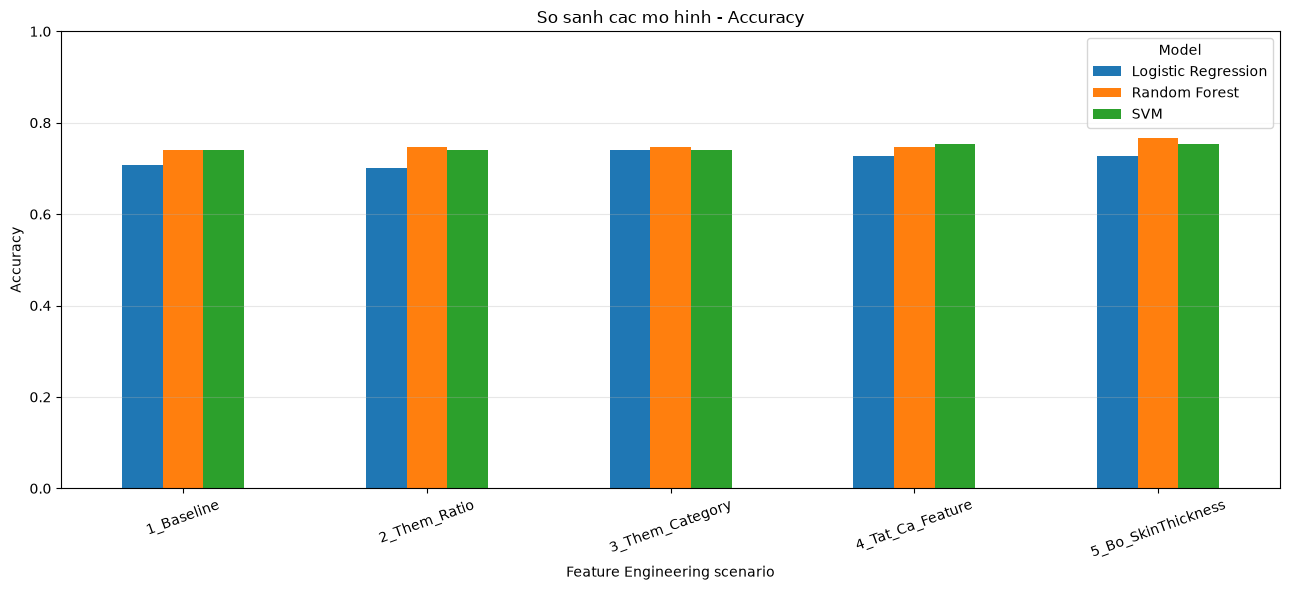

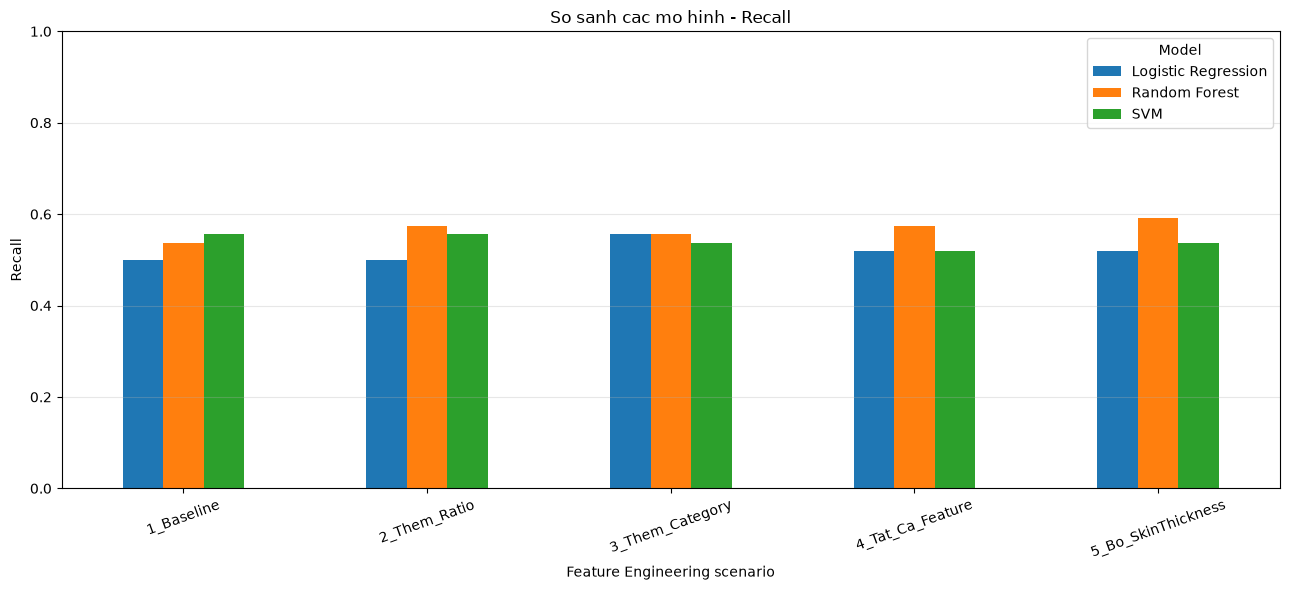

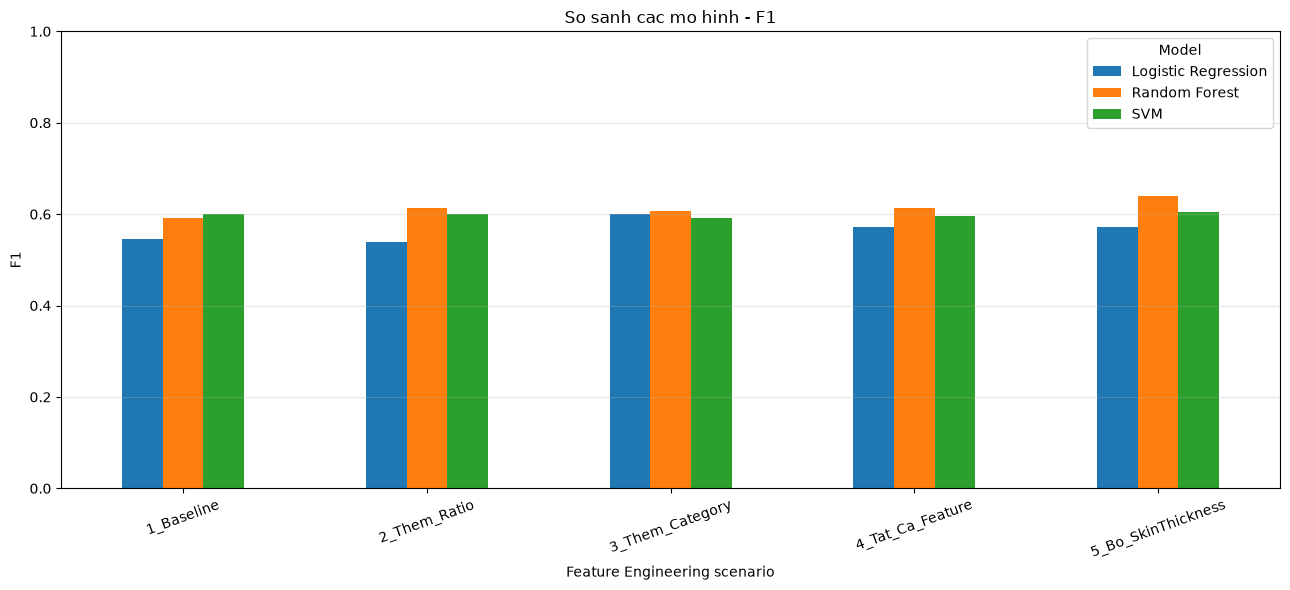

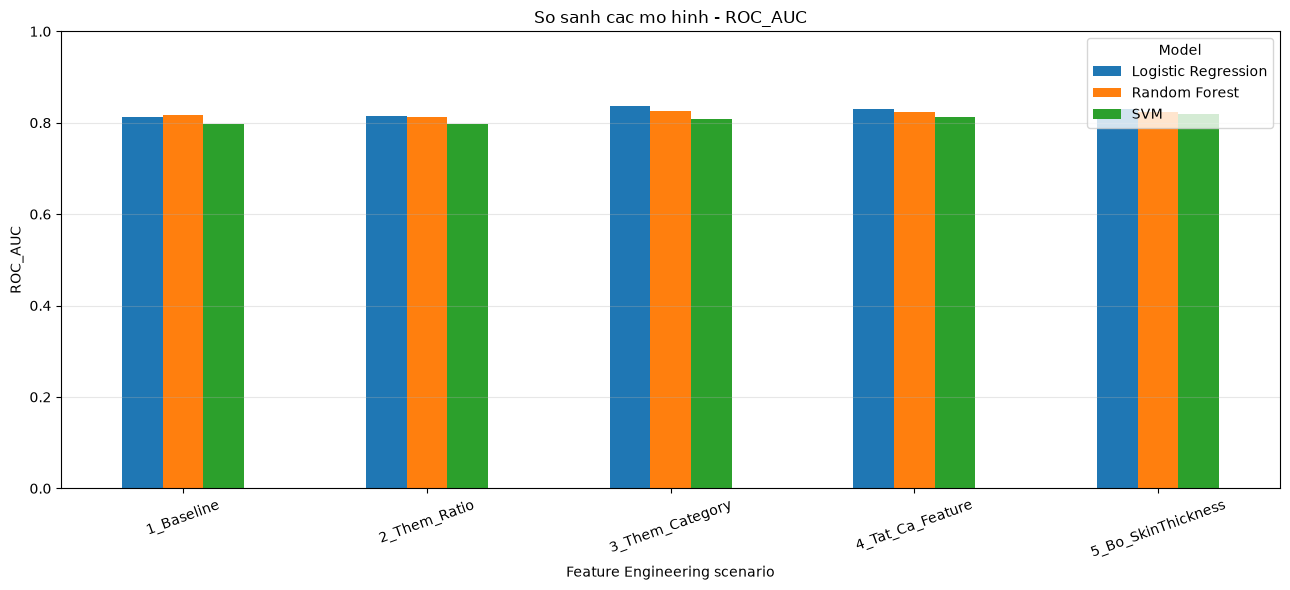


KET QUA DANH GIA 3 MO HINH


,Ten_Thu_Nghiem,Mo_Hinh,So_Luong_Feature,Accuracy,Recall,F1,ROC_AUC
0,3_Them_Category,Logistic Regression,16,0.7403,0.5556,0.6000,0.8369
1,5_Bo_SkinThickness,Logistic Regression,17,0.7273,0.5185,0.5714,0.8304
2,4_Tat_Ca_Feature,Logistic Regression,18,0.7273,0.5185,0.5714,0.8294
3,3_Them_Category,Random Forest,16,0.7468,0.5556,0.6061,0.8261
4,5_Bo_SkinThickness,Random Forest,17,0.7662,0.5926,0.6400,0.8244
5,4_Tat_Ca_Feature,Random Forest,18,0.7468,0.5741,0.6139,0.8224
6,5_Bo_SkinThickness,SVM,17,0.7532,0.5370,0.6042,0.8191
7,1_Baseline,Random Forest,8,0.7403,0.5370,0.5918,0.8158
8,2_Them_Ratio,Logistic Regression,9,0.7013,0.5000,0.5400,0.8152
9,2_Them_Ratio,Random Forest,9,0.7468,0.5741,0.6139,0.8132



TOP 5 THEO ROC-AUC


,Ten_Thu_Nghiem,Mo_Hinh,So_Luong_Feature,Accuracy,Recall,F1,ROC_AUC
0,3_Them_Category,Logistic Regression,16,0.7403,0.5556,0.6000,0.8369
1,5_Bo_SkinThickness,Logistic Regression,17,0.7273,0.5185,0.5714,0.8304
2,4_Tat_Ca_Feature,Logistic Regression,18,0.7273,0.5185,0.5714,0.8294
3,3_Them_Category,Random Forest,16,0.7468,0.5556,0.6061,0.8261
4,5_Bo_SkinThickness,Random Forest,17,0.7662,0.5926,0.6400,0.8244



MO HINH CO ROC-AUC CAO NHAT TREN CAC THU NGHIEM
Feature scenario: 3_Them_Category
Model: Logistic Regression
Accuracy: 0.7403
Recall:   0.5556
F1-score: 0.6000
ROC-AUC:  0.8369

HOAN THANH VIEC 13

Thu muc ket qua:
C:\HocMay\Do_An_Hoc_May\Model\Viec13

File CSV:
 - baseline_model_results.csv
 - classification_report.csv
 - dataset_summary.csv
 - feature_experiment_results.csv
 - feature_experiment_summary.csv
 - missing_values.csv

File bieu do:
 - comparison_accuracy.png
 - comparison_f1.png
 - comparison_recall.png
 - comparison_roc_auc.png
 - confusion_matrix_1_Baseline_logistic_regression.png
 - confusion_matrix_1_Baseline_random_forest.png
 - confusion_matrix_1_Baseline_svm.png
 - confusion_matrix_2_Them_Ratio_logistic_regression.png
 - confusion_matrix_2_Them_Ratio_random_forest.png
 - confusion_matrix_2_Them_Ratio_svm.png
 - confusion_matrix_3_Them_Category_logistic_regression.png
 - confusion_matrix_3_Them_Category_random_forest.png
 - confusion_matrix_3_Them_Category_svm.png


In [40]:

# ============================================================
# VIEC 13 - BASELINE MODEL EVALUATION
# Logistic Regression | Random Forest | SVM
# Dataset: Pima Indians Diabetes
# Chay truc tiep trong EDA.ipynb - khong dung __file__
# ============================================================

import os
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. CAU HINH DU AN VA THU MUC LUU
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20

CURRENT_DIR = Path.cwd().resolve()


def find_project_root(start):
    """
    Tim thu muc goc co Feature_Engineering hoac Model.
    Ho tro notebook dat trong project hoac cac thu muc con.
    """
    for p in [start, *start.parents]:
        if (
            (p / "Feature_Engineering").is_dir()
            or (p / "Model").is_dir()
        ):
            return p

    return start


PROJECT_ROOT = find_project_root(CURRENT_DIR)

# Thu muc output uu tien theo cau truc project trong anh
OUTPUT_CANDIDATES = [
    PROJECT_ROOT / "Model" / "Tien_Xu_Li" / "Viec13",
    PROJECT_ROOT / "Model" / "Viec13",
    PROJECT_ROOT / "Tien_Xu_Li" / "Viec13",
]

# Neu Viec13 da ton tai thi dung no.
# Neu chua co, tao tai vi tri dau tien.
OUTPUT_DIR = next(
    (p for p in OUTPUT_CANDIDATES if p.is_dir()),
    OUTPUT_CANDIDATES[0]
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_DIR = OUTPUT_DIR / "models"
PLOT_DIR = OUTPUT_DIR / "plots"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("VIEC 13 - BASELINE MODEL EVALUATION")
print("=" * 70)
print("Notebook directory:", CURRENT_DIR)
print("Project root:", PROJECT_ROOT)
print("Output directory:", OUTPUT_DIR)


# ============================================================
# 2. TIM FILE DATASET
# ============================================================

DATASET_NAMES = [
    "pima-indians-diabetes.csv",
    "diabetes.csv",
    "pima.csv",
]


def read_csv_robust(path):
    """
    Thu doc CSV bang cach tu phat hien separator.
    Neu khong thanh cong thi thu cac separator pho bien.
    """
    errors = []

    for kwargs in [
        {"sep": None, "engine": "python"},
        {"sep": ","},
        {"sep": ";"},
        {"sep": "\t"},
    ]:
        try:
            data = pd.read_csv(path, **kwargs)

            # Neu header bi gom thanh mot cot co dau phay
            if data.shape[1] == 1:
                first_col = str(data.columns[0])

                if "," in first_col:
                    retry = pd.read_csv(path, sep=",")
                    if retry.shape[1] > 1:
                        return retry

                if ";" in first_col:
                    retry = pd.read_csv(path, sep=";")
                    if retry.shape[1] > 1:
                        return retry

            if data.shape[1] > 1:
                return data

        except Exception as exc:
            errors.append(str(exc))

    raise ValueError(
        f"Khong doc duoc file CSV: {path}\n{errors}"
    )


def normalize_column_name(name):
    return (
        str(name)
        .strip()
        .replace("\ufeff", "")
        .replace(" ", "")
        .replace("-", "_")
        .lower()
    )


def find_dataset():
    """
    Tim dataset Pima trong project.
    Khong su dung file tong hop ket qua cua Viec9.
    """

    # Uu tien cac vi tri thuong gap
    preferred = [
        PROJECT_ROOT / "Model" / "Tien_Xu_Li"
        / "pima-indians-diabetes.csv",

        PROJECT_ROOT / "Model"
        / "pima-indians-diabetes.csv",

        PROJECT_ROOT / "Model" / "Tien_Xu_Li"
        / "Viec6" / "pima-indians-diabetes.csv",

        PROJECT_ROOT / "Feature_Engineering"
        / "Viec9" / "pima-indians-diabetes.csv",

        PROJECT_ROOT / "Feature_Engineering"
        / "Viec9" / "bang_baseline_feature_set.csv",
    ]

    for path in preferred:
        if path.is_file():
            try:
                sample = read_csv_robust(path)
                cols = {
                    normalize_column_name(c)
                    for c in sample.columns
                }

                target_exists = bool(
                    cols.intersection(
                        {"class", "outcome", "diabetes", "target"}
                    )
                )

                if target_exists and len(cols) >= 5:
                    return path
            except Exception:
                continue

    excluded_dirs = {
        ".git",
        ".venv",
        "venv",
        "__pycache__",
        "models",
        "plots",
        ".ipynb_checkpoints",
    }

    # Tim trong project
    for root in [PROJECT_ROOT, CURRENT_DIR]:
        if not root.exists():
            continue

        for path in root.rglob("*.csv"):

            if any(
                part.lower() in excluded_dirs
                for part in path.parts
            ):
                continue

            try:
                sample = read_csv_robust(path)

                cols = {
                    normalize_column_name(c)
                    for c in sample.columns
                }

                has_glucose = "glucose" in cols
                has_bmi = "bmi" in cols
                has_target = bool(
                    cols.intersection(
                        {"class", "outcome", "diabetes", "target"}
                    )
                )

                if has_glucose and has_bmi and has_target:
                    return path

            except Exception:
                continue

    raise FileNotFoundError(
        "Khong tim thay dataset Pima Indians Diabetes.\n"
        "Hay kiem tra file CSV trong project, "
        "dac biet la pima-indians-diabetes.csv."
    )


DATA_PATH = find_dataset()

df = read_csv_robust(DATA_PATH)

# Chuan hoa ten cot
df.columns = [
    str(c).strip().replace("\ufeff", "")
    for c in df.columns
]

print("\nDataset duoc su dung:", DATA_PATH)
print("Kich thuoc ban dau:", df.shape)
print("Cac cot ban dau:", df.columns.tolist())

# Neu van con mot cot gom tat ca ten truong
if df.shape[1] == 1 and "," in str(df.columns[0]):
    df = pd.read_csv(DATA_PATH, sep=",")
    df.columns = [
        str(c).strip().replace("\ufeff", "")
        for c in df.columns
    ]

print("Kich thuoc sau khi doc:", df.shape)
print("Cac cot sau khi doc:", df.columns.tolist())

if df.shape[1] < 2:
    raise ValueError(
        "CSV van chi co mot cot. "
        "Hay kiem tra delimiter va noi dung file."
    )


# ============================================================
# 3. CHUAN HOA COT VA XAC DINH TARGET
# ============================================================

rename_map = {}

for col in df.columns:
    normalized = normalize_column_name(col)

    aliases = {
        "pregnancies": "Pregnancies",
        "glucose": "Glucose",
        "bloodpressure": "BloodPressure",
        "blood_pressure": "BloodPressure",
        "skinthickness": "SkinThickness",
        "skin_thickness": "SkinThickness",
        "insulin": "Insulin",
        "bmi": "BMI",
        "diabetespedigreefunction": "DiabetesPedigreeFunction",
        "diabetes_pedigree_function": "DiabetesPedigreeFunction",
        "age": "Age",
        "class": "Class",
        "outcome": "Outcome",
        "diabetes": "Diabetes",
        "target": "Target",
    }

    if normalized in aliases:
        rename_map[col] = aliases[normalized]

df = df.rename(columns=rename_map)

TARGET_CANDIDATES = [
    "Class",
    "Outcome",
    "Diabetes",
    "Target",
]

TARGET_COL = next(
    (c for c in TARGET_CANDIDATES if c in df.columns),
    None
)

if TARGET_COL is None:
    raise ValueError(
        "Khong tim thay cot nhan Class/Outcome/Diabetes/Target.\n"
        f"Cac cot hien co: {df.columns.tolist()}"
    )

BASE_FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]

missing_cols = [
    col for col in BASE_FEATURES
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Dataset thieu cac cot: {missing_cols}\n"
        f"Cac cot hien co: {df.columns.tolist()}"
    )

# Chuyen du lieu thanh numeric
for col in BASE_FEATURES + [TARGET_COL]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Bo dong khong co nhan
df = df.dropna(subset=[TARGET_COL]).copy()

# Nhan nhi phan 0 va 1
df = df[df[TARGET_COL].isin([0, 1])].copy()
df[TARGET_COL] = df[TARGET_COL].astype(int)

# Chi su dung cac cot can thiet
df = df[BASE_FEATURES + [TARGET_COL]].copy()

print("\nCot target:", TARGET_COL)
print("Kich thuoc dataset:", df.shape)
print("\nPhan bo target:")
print(df[TARGET_COL].value_counts().sort_index())


# ============================================================
# 4. XU LY CAC GIA TRI 0 BAT THUONG
# ============================================================

# Theo quy uoc bo du lieu Pima:
# 0 o cac cot nay duoc xem la gia tri thieu bat thuong.
# Pregnancies = 0 van la gia tri hop le.

ZERO_AS_MISSING = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

for col in ZERO_AS_MISSING:
    df.loc[df[col] == 0, col] = np.nan

# Luu thong tin dataset
df.describe().to_csv(
    OUTPUT_DIR / "dataset_summary.csv",
    encoding="utf-8-sig"
)

df.isna().sum().rename("Missing_Count").to_csv(
    OUTPUT_DIR / "missing_values.csv",
    encoding="utf-8-sig"
)

print("\nSo gia tri thieu theo cot:")
print(df.isna().sum())


# ============================================================
# 5. CHIA TRAIN VA TEST
# ============================================================

X = df[BASE_FEATURES].copy()
y = df[TARGET_COL].copy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nSo mau train:", len(X_train_raw))
print("So mau test :", len(X_test_raw))


# ============================================================
# 6. FEATURE ENGINEERING - VIEC 9
# ============================================================

SCENARIOS = {
    "1_Baseline": "8 feature goc",
    "2_Them_Ratio": "Them Glucose_BMI_Ratio",
    "3_Them_Category": "Them Ratio va Category BMI/Age",
    "4_Tat_Ca_Feature": "Them Ratio va Category va feature phu",
    "5_Bo_SkinThickness": "Feature engineered, bo SkinThickness",
}


def make_features(X_input, scenario):
    """
    Tao feature tu du lieu goc.
    Khong su dung target trong feature engineering.
    """

    Z = X_input[BASE_FEATURES].copy()

    # Ratio co xu ly chia cho 0
    if scenario in [
        "2_Them_Ratio",
        "3_Them_Category",
        "4_Tat_Ca_Feature",
        "5_Bo_SkinThickness",
    ]:
        Z["Glucose_BMI_Ratio"] = (
            Z["Glucose"]
            / Z["BMI"].replace(0, np.nan)
        )

    # Category BMI va Age
    if scenario in [
        "3_Them_Category",
        "4_Tat_Ca_Feature",
        "5_Bo_SkinThickness",
    ]:
        bmi_category = pd.cut(
            Z["BMI"],
            bins=[-np.inf, 18.5, 25, 30, np.inf],
            labels=[
                "Underweight",
                "Normal",
                "Overweight",
                "Obese",
            ],
        )

        age_category = pd.cut(
            Z["Age"],
            bins=[-np.inf, 30, 45, np.inf],
            labels=[
                "Young",
                "Middle",
                "Older",
            ],
        )

        Z["BMI_Category"] = bmi_category.astype("object")
        Z["Age_Category"] = age_category.astype("object")

    # Them feature phu cho kich ban 4 va 5
    if scenario in [
        "4_Tat_Ca_Feature",
        "5_Bo_SkinThickness",
    ]:
        Z["Glucose_Insulin_Ratio"] = (
            Z["Glucose"]
            / Z["Insulin"].replace(0, np.nan)
        )

        Z["Age_BMI_Ratio"] = (
            Z["Age"]
            / Z["BMI"].replace(0, np.nan)
        )

    # Loai bo SkinThickness neu duoc yeu cau
    if scenario == "5_Bo_SkinThickness":
        Z = Z.drop(
            columns=["SkinThickness"],
            errors="ignore",
        )

    # Chuyen category thanh one-hot
    categorical_cols = [
        col for col in ["BMI_Category", "Age_Category"]
        if col in Z.columns
    ]

    if categorical_cols:
        Z = pd.get_dummies(
            Z,
            columns=categorical_cols,
            dtype=int,
        )

    return Z


# ============================================================
# 7. DINH NGHIA CAC MO HINH
# ============================================================

MODELS = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE,
        )),
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            random_state=RANDOM_STATE,
        )),
    ]),
}


# ============================================================
# 8. HUAN LUYEN VA DANH GIA 15 TRUONG HOP
# ============================================================

all_results = []
classification_reports = []
feature_summaries = []

for scenario, description in SCENARIOS.items():

    print("\n" + "=" * 70)
    print("KICH BAN:", scenario)
    print(description)
    print("=" * 70)

    X_train = make_features(X_train_raw, scenario)
    X_test = make_features(X_test_raw, scenario)

    # Dam bao train va test co cung tap cot
    X_test = X_test.reindex(
        columns=X_train.columns,
        fill_value=0,
    )

    # Ep cac cot thanh so
    X_train = X_train.apply(
        pd.to_numeric,
        errors="coerce",
    )

    X_test = X_test.apply(
        pd.to_numeric,
        errors="coerce",
    )

    feature_summaries.append({
        "Ten_Thu_Nghiem": scenario,
        "Mo_Ta": description,
        "So_Luong_Feature": len(X_train.columns),
        "Danh_Sach_Feature": ", ".join(X_train.columns),
    })

    print("So feature:", len(X_train.columns))

    for model_name, pipeline_template in MODELS.items():

        print("\nDang huan luyen:", model_name)

        model = clone(pipeline_template)
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        # Lay score cho ROC-AUC
        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(X_test)[:, 1]
        else:
            y_score = model.decision_function(X_test)

        # Cac metric danh gia
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test,
            y_pred,
            zero_division=0,
        )

        recall = recall_score(
            y_test,
            y_pred,
            zero_division=0,
        )

        f1 = f1_score(
            y_test,
            y_pred,
            zero_division=0,
        )

        roc_auc = roc_auc_score(
            y_test,
            y_score,
        )

        result = {
            "Ten_Thu_Nghiem": scenario,
            "Mo_Ta": description,
            "Mo_Hinh": model_name,
            "So_Luong_Feature": len(X_train.columns),
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "ROC_AUC": roc_auc,
        }

        all_results.append(result)

        print(
            f"Accuracy={accuracy:.4f} | "
            f"Precision={precision:.4f} | "
            f"Recall={recall:.4f} | "
            f"F1={f1:.4f} | "
            f"ROC-AUC={roc_auc:.4f}"
        )

        # Classification report
        report = classification_report(
            y_test,
            y_pred,
            output_dict=True,
            zero_division=0,
        )

        for label, values in report.items():
            if isinstance(values, dict):
                classification_reports.append({
                    "Ten_Thu_Nghiem": scenario,
                    "Mo_Hinh": model_name,
                    "Class": label,
                    **values,
                })

        # Ten file
        safe_model_name = (
            model_name.lower()
            .replace(" ", "_")
            .replace("(", "")
            .replace(")", "")
        )

        # Luu model cung danh sach cot dau vao
        artifact = {
            "model": model,
            "features": X_train.columns.tolist(),
            "scenario": scenario,
            "model_name": model_name,
            "target": TARGET_COL,
            "zero_as_missing": ZERO_AS_MISSING,
        }

        joblib.dump(
            artifact,
            MODEL_DIR / f"{scenario}_{safe_model_name}.joblib",
        )

        # Confusion matrix
        fig, ax = plt.subplots(figsize=(5, 4))

        ConfusionMatrixDisplay(
            confusion_matrix=confusion_matrix(
                y_test,
                y_pred,
                labels=[0, 1],
            ),
            display_labels=[0, 1],
        ).plot(
            ax=ax,
            cmap="Blues",
            colorbar=False,
        )

        ax.set_title(f"{model_name} - {scenario}")
        fig.tight_layout()

        fig.savefig(
            PLOT_DIR
            / f"confusion_matrix_{scenario}_{safe_model_name}.png",
            dpi=150,
            bbox_inches="tight",
        )

        plt.close(fig)

        # ROC curve
        fig, ax = plt.subplots(figsize=(6, 5))

        RocCurveDisplay.from_predictions(
            y_test,
            y_score,
            name=model_name,
            ax=ax,
        )

        ax.set_title(f"ROC Curve - {scenario}")
        fig.tight_layout()

        fig.savefig(
            PLOT_DIR
            / f"roc_curve_{scenario}_{safe_model_name}.png",
            dpi=150,
            bbox_inches="tight",
        )

        plt.close(fig)


# ============================================================
# 9. LUU BANG KET QUA
# ============================================================

results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    by=["ROC_AUC", "F1", "Recall"],
    ascending=False,
).reset_index(drop=True)

results_df.to_csv(
    OUTPUT_DIR / "baseline_model_results.csv",
    index=False,
    encoding="utf-8-sig",
)

feature_df = pd.DataFrame(feature_summaries)

feature_df.to_csv(
    OUTPUT_DIR / "feature_experiment_results.csv",
    index=False,
    encoding="utf-8-sig",
)

report_df = pd.DataFrame(classification_reports)

report_df.to_csv(
    OUTPUT_DIR / "classification_report.csv",
    index=False,
    encoding="utf-8-sig",
)

# Bang tong hop trung binh 3 mo hinh theo tung scenario
feature_summary = (
    results_df
    .groupby("Ten_Thu_Nghiem", as_index=False)
    .agg(
        So_Luong_Feature=("So_Luong_Feature", "first"),
        Accuracy_Trung_Binh=("Accuracy", "mean"),
        Recall_Trung_Binh=("Recall", "mean"),
        F1_Trung_Binh=("F1", "mean"),
        ROC_AUC_Trung_Binh=("ROC_AUC", "mean"),
    )
)

feature_summary.to_csv(
    OUTPUT_DIR / "feature_experiment_summary.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 10. VE BIEU DO SO SANH CAC MO HINH
# ============================================================

metrics = [
    ("Accuracy", "accuracy"),
    ("Recall", "recall"),
    ("F1", "f1"),
    ("ROC_AUC", "roc_auc"),
]

for metric_col, file_suffix in metrics:

    pivot = results_df.pivot(
        index="Ten_Thu_Nghiem",
        columns="Mo_Hinh",
        values=metric_col,
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(13, 6),
        rot=20,
    )

    ax.set_title(f"So sanh cac mo hinh - {metric_col}")
    ax.set_xlabel("Feature Engineering scenario")
    ax.set_ylabel(metric_col)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Model")

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR / f"comparison_{file_suffix}.png",
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()


# ============================================================
# 11. LUU CAU HINH THUC NGHIEM
# ============================================================

config = {
    "dataset_path": str(DATA_PATH),
    "target_column": TARGET_COL,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "train_rows": int(len(X_train_raw)),
    "test_rows": int(len(X_test_raw)),
    "original_features": BASE_FEATURES,
    "zero_as_missing": ZERO_AS_MISSING,
    "models": list(MODELS.keys()),
    "scenarios": SCENARIOS,
}

with open(
    OUTPUT_DIR / "experiment_config.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        config,
        f,
        ensure_ascii=False,
        indent=4,
    )


# ============================================================
# 12. HIEN THI KET QUA
# ============================================================

display_columns = [
    "Ten_Thu_Nghiem",
    "Mo_Hinh",
    "So_Luong_Feature",
    "Accuracy",
    "Recall",
    "F1",
    "ROC_AUC",
]

print("\n" + "=" * 100)
print("KET QUA DANH GIA 3 MO HINH")
print("=" * 100)

display(
    results_df[display_columns].round(4)
)

print("\n" + "=" * 100)
print("TOP 5 THEO ROC-AUC")
print("=" * 100)

display(
    results_df[display_columns].head(5).round(4)
)

best_result = results_df.iloc[0]

print("\nMO HINH CO ROC-AUC CAO NHAT TREN CAC THU NGHIEM")
print("Feature scenario:", best_result["Ten_Thu_Nghiem"])
print("Model:", best_result["Mo_Hinh"])
print(f"Accuracy: {best_result['Accuracy']:.4f}")
print(f"Recall:   {best_result['Recall']:.4f}")
print(f"F1-score: {best_result['F1']:.4f}")
print(f"ROC-AUC:  {best_result['ROC_AUC']:.4f}")


# ============================================================
# 13. DANH SACH FILE DA LUU
# ============================================================

print("\n" + "=" * 70)
print("HOAN THANH VIEC 13")
print("=" * 70)

print("\nThu muc ket qua:")
print(OUTPUT_DIR)

print("\nFile CSV:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", path.name)

print("\nFile bieu do:")
for path in sorted(PLOT_DIR.glob("*.png")):
    print(" -", path.name)

print("\nFile model:")
for path in sorted(MODEL_DIR.glob("*.joblib")):
    print(" -", path.name)


VIEC 14 - STRATIFIED K-FOLD & GRIDSEARCHCV
Project root: C:\HocMay\Do_An_Hoc_May
Viec 13: C:\HocMay\Do_An_Hoc_May\Model\Viec13
Thu muc output: C:\HocMay\Do_An_Hoc_May\Model\Viec14

Dataset: C:\HocMay\Do_An_Hoc_May\Tien_Xu_Li\Viec_5\pima_indians_zero_as_missing_NaN.csv
Kich thuoc: (768, 9)
Target: Class

Phan bo target:
Class
0    500
1    268
Name: count, dtype: int64

Ket qua tham chieu tu viec 13: C:\HocMay\Do_An_Hoc_May\Model\Viec13\baseline_model_results.csv
ROC-AUC trung binh theo scenario:
Ten_Thu_Nghiem
5_Bo_SkinThickness    0.824630
3_Them_Category       0.823580
4_Tat_Ca_Feature      0.821636
2_Them_Ratio          0.808796
1_Baseline            0.808395
Name: ROC_AUC, dtype: float64
Scenario duoc chon: 5_Bo_SkinThickness

Scenario su dung: 5_Bo_SkinThickness
So feature: 17
So mau train: 614
So mau test: 154

StratifiedKFold:
So fold: 5
Shuffle: True
Random state: 42

Phan bo lop theo fold:


,Fold,Train_Size,Validation_Size,Train_Class_0,Train_Class_1,Validation_Class_0,Validation_Class_1,Train_Class_1_Ratio,Validation_Class_1_Ratio
0,1,491,123,320,171,80,43,0.3483,0.3496
1,2,491,123,320,171,80,43,0.3483,0.3496
2,3,491,123,320,171,80,43,0.3483,0.3496
3,4,491,123,320,171,80,43,0.3483,0.3496
4,5,492,122,320,172,80,42,0.3496,0.3443



GRID SEARCH: Logistic Regression
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Tham so tot nhat:
{'model__C': 0.1, 'model__class_weight': 'balanced', 'model__solver': 'liblinear'}
Best CV ROC-AUC: 0.8473
Test ROC-AUC: 0.8354
Test Accuracy: 0.7727

GRID SEARCH: Random Forest
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Tham so tot nhat:
{'model__class_weight': None, 'model__max_depth': 10, 'model__min_samples_leaf': 3, 'model__n_estimators': 300}
Best CV ROC-AUC: 0.8328
Test ROC-AUC: 0.8313
Test Accuracy: 0.7662

GRID SEARCH: SVM (RBF)
Fitting 5 folds for each of 18 candidates, totalling 90 fits

Tham so tot nhat:
{'model__C': 1.0, 'model__class_weight': 'balanced', 'model__gamma': 0.01}
Best CV ROC-AUC: 0.8499
Test ROC-AUC: 0.8280
Test Accuracy: 0.7792

BANG TONG HOP GRIDSEARCHCV


,Mo_Hinh,Best_Class_Weight,Best_CV_Accuracy,Best_CV_Recall,Best_CV_F1,Best_CV_ROC_AUC,Test_Accuracy,Test_Recall,Test_F1,Test_ROC_AUC
0,SVM (RBF),balanced,0.7687,0.7664,0.6984,0.8499,0.7792,0.7963,0.7167,0.8280
1,Logistic Regression,balanced,0.7638,0.7663,0.6938,0.8473,0.7727,0.7778,0.7059,0.8354
2,Random Forest,None,0.7638,0.6028,0.6403,0.8328,0.7662,0.5926,0.6400,0.8313



SO SANH CLASS_WEIGHT


,Mo_Hinh,Class_Weight,CV_Accuracy,CV_Recall,CV_F1,CV_ROC_AUC
0,Logistic Regression,None,0.7671,0.5843,0.6363,0.8458
1,Logistic Regression,balanced,0.7638,0.7663,0.6938,0.8473
2,Random Forest,None,0.7638,0.6028,0.6403,0.8328
3,Random Forest,balanced,0.7638,0.7147,0.6790,0.8294
4,SVM (RBF),None,0.6645,0.0515,0.0942,0.8455
5,SVM (RBF),balanced,0.7687,0.7664,0.6984,0.8499


Da luu: Viec14_Bang_Tong_Hop_GridSearchCV.png
Da luu: Viec14_Bang_Tham_So_Toi_Uu.png
Da luu: Viec14_Bang_So_Sanh_Class_Weight.png


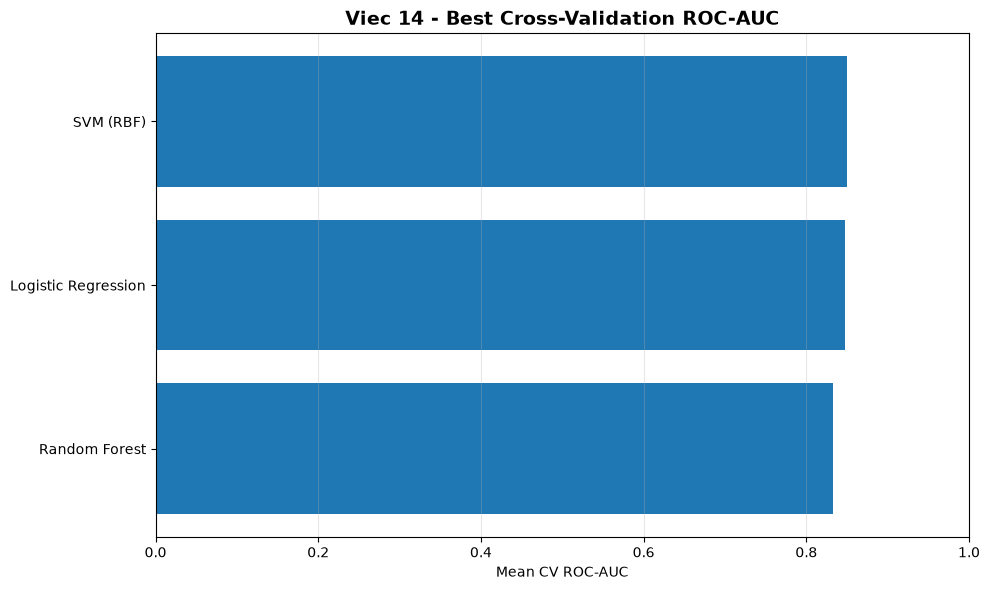

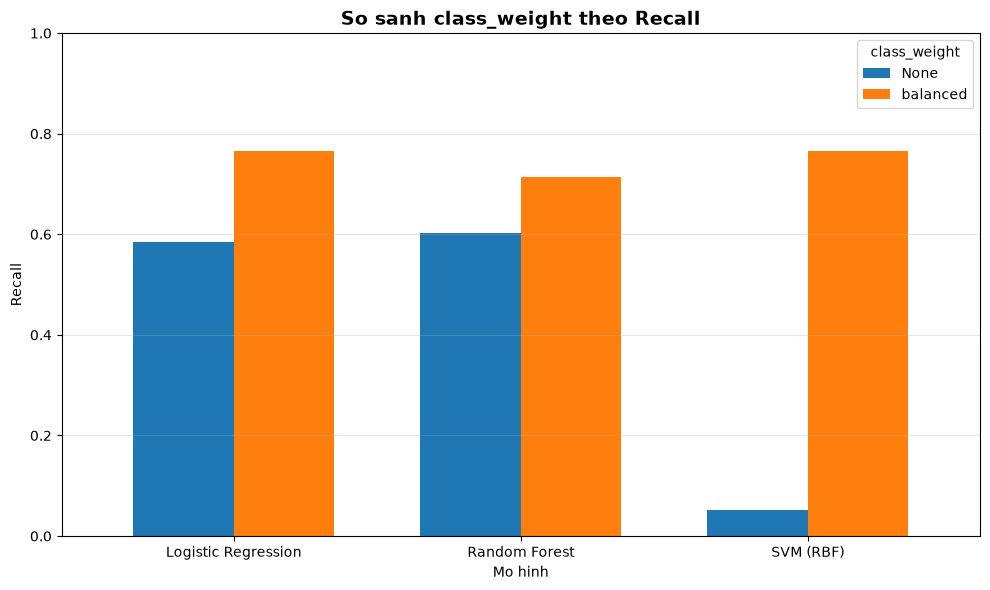

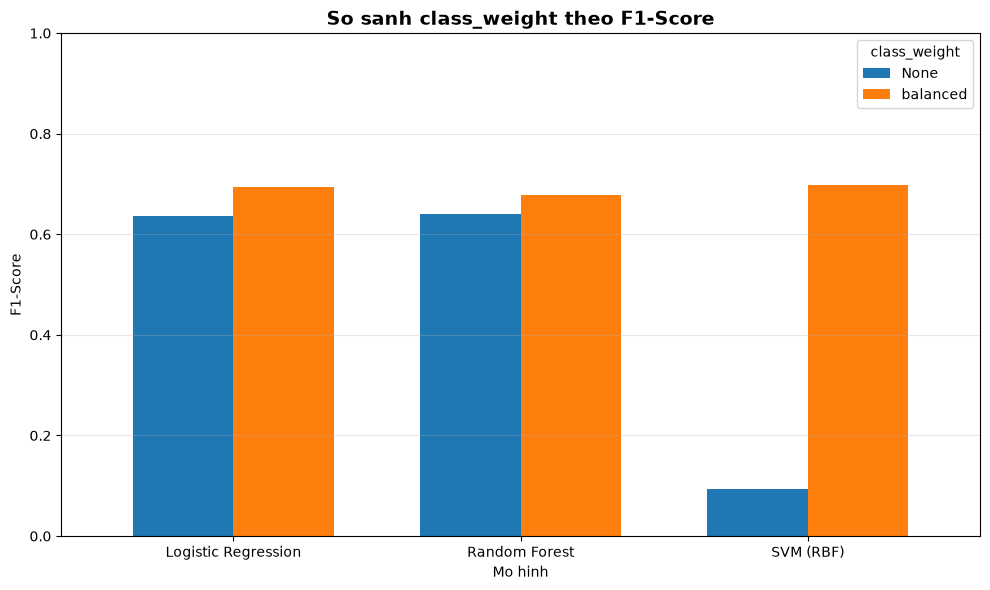

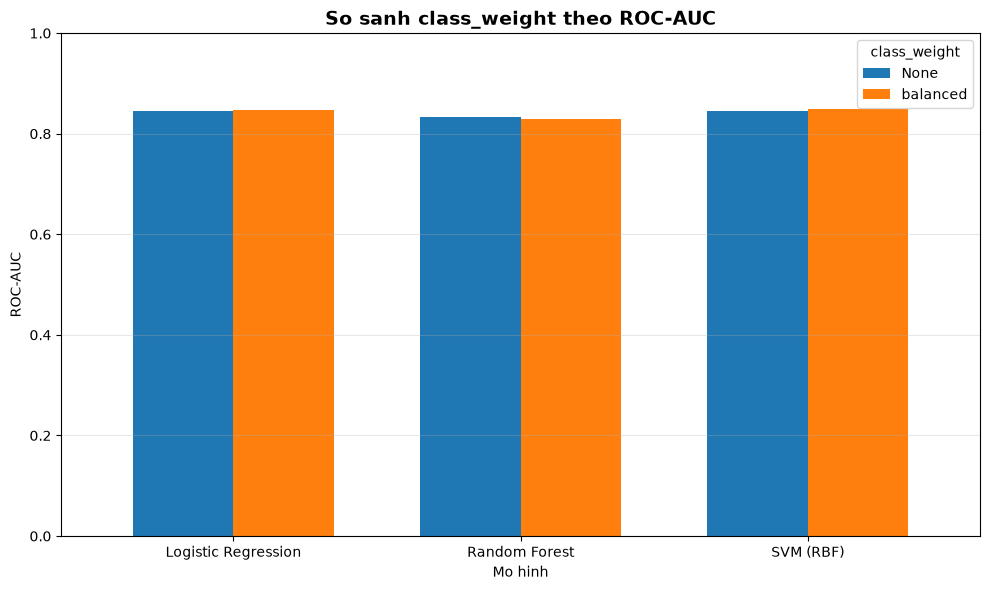


KET QUA TOT NHAT THEO BEST CV ROC-AUC
Model: SVM (RBF)
Feature scenario: 5_Bo_SkinThickness
Class weight: balanced
Best CV ROC-AUC: 0.8499
Test ROC-AUC: 0.8280
Test Accuracy: 0.7792
Test Recall: 0.7963
Test F1: 0.7167

Bang tong hop:


,Mo_Hinh,Scenario,So_Feature,Best_Class_Weight,Best_CV_Accuracy,Best_CV_Precision,Best_CV_Recall,Best_CV_F1,Best_CV_ROC_AUC,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC,Best_Params,Best_Index
0,SVM (RBF),5_Bo_SkinThickness,17,balanced,0.7687,0.6444,0.7664,0.6984,0.8499,0.7792,0.6515,0.7963,0.7167,0.8280,"{""model__C"": 1.0, ""model__class_weight"": ""bala...",10
1,Logistic Regression,5_Bo_SkinThickness,17,balanced,0.7638,0.6361,0.7663,0.6938,0.8473,0.7727,0.6462,0.7778,0.7059,0.8354,"{""model__C"": 0.1, ""model__class_weight"": ""bala...",1
2,Random Forest,5_Bo_SkinThickness,17,None,0.7638,0.6863,0.6028,0.6403,0.8328,0.7662,0.6957,0.5926,0.6400,0.8313,"{""model__class_weight"": null, ""model__max_dept...",7



Bang so sanh class_weight:


,Mo_Hinh,Class_Weight,CV_Accuracy,CV_Recall,CV_F1,CV_ROC_AUC
0,Logistic Regression,None,0.7671,0.5843,0.6363,0.8458
1,Logistic Regression,balanced,0.7638,0.7663,0.6938,0.8473
2,Random Forest,None,0.7638,0.6028,0.6403,0.8328
3,Random Forest,balanced,0.7638,0.7147,0.6790,0.8294
4,SVM (RBF),None,0.6645,0.0515,0.0942,0.8455
5,SVM (RBF),balanced,0.7687,0.7664,0.6984,0.8499



HOAN THANH VIEC 14
Thu muc ket qua: C:\HocMay\Do_An_Hoc_May\Model\Viec14

File PNG:
 - Viec14_Bang_So_Sanh_Class_Weight.png
 - Viec14_Bang_Tham_So_Toi_Uu.png
 - Viec14_Bang_Tong_Hop_GridSearchCV.png
 - Viec14_ClassWeight_F1.png
 - Viec14_ClassWeight_Recall.png
 - Viec14_ClassWeight_ROC_AUC.png
 - Viec14_So_Sanh_Best_CV_ROC_AUC.png

File CSV:
 - StratifiedKFold_Phan_Bo_Lop.csv
 - Viec14_Bo_Tham_So_Toi_Uu.csv
 - Viec14_Class_Weight_Tot_Nhat.csv
 - Viec14_Classification_Report_Test.csv
 - Viec14_GridSearchCV_Tong_Hop.csv
 - Viec14_So_Sanh_Class_Weight.csv
 - Viec14_Toan_Bo_CV_Results.csv

File model:
 - Viec14_Best_logistic_regression.joblib
 - Viec14_Best_random_forest.joblib
 - Viec14_Best_svm_rbf.joblib


In [41]:

# ============================================================
# VIEC 14 - STRATIFIED K-FOLD & GRIDSEARCHCV
# Dataset: Pima Indians Diabetes
# Models: Logistic Regression, Random Forest, SVM
# Comparison: class_weight=None vs class_weight="balanced"
# Based on VIEC 13
# Output: Model/Viec14/
# Khong dung __file__, chay truc tiep trong EDA.ipynb
# Khong dung SMOTE mac dinh
# ============================================================

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from IPython.display import display, Image as IPyImage

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. CAU HINH DU AN VA THU MUC
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5
N_JOBS = -1

CURRENT_DIR = Path.cwd().resolve()


def find_project_root(start):
    for path in [start, *start.parents]:
        if (path / "Feature_Engineering").is_dir():
            return path
        if (
            (path / "Model").is_dir()
            and (path / "Tien_Xu_Li").is_dir()
        ):
            return path
    return start


PROJECT_ROOT = find_project_root(CURRENT_DIR)

# Neu EDA.ipynb nam o thu muc goc cua project.
OUTPUT_DIR = PROJECT_ROOT / "Model" / "Viec14"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

VIEC13_DIR = PROJECT_ROOT / "Model" / "Viec13"

print("=" * 75)
print("VIEC 14 - STRATIFIED K-FOLD & GRIDSEARCHCV")
print("=" * 75)
print("Project root:", PROJECT_ROOT)
print("Viec 13:", VIEC13_DIR)
print("Thu muc output:", OUTPUT_DIR)


# ============================================================
# 2. TIM VA DOC DATASET GOC
# ============================================================

TARGET_NAMES = {"class", "outcome", "diabetes", "target"}

ALIASES = {
    "pregnancies": "Pregnancies",
    "glucose": "Glucose",
    "bloodpressure": "BloodPressure",
    "blood_pressure": "BloodPressure",
    "skinthickness": "SkinThickness",
    "skin_thickness": "SkinThickness",
    "insulin": "Insulin",
    "bmi": "BMI",
    "diabetespedigreefunction": "DiabetesPedigreeFunction",
    "diabetes_pedigree_function": "DiabetesPedigreeFunction",
    "age": "Age",
    "class": "Class",
    "outcome": "Outcome",
    "diabetes": "Diabetes",
    "target": "Target",
}

BASE_FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]


def normalize_name(name):
    return (
        str(name)
        .strip()
        .replace("\ufeff", "")
        .replace(" ", "")
        .replace("-", "_")
        .lower()
    )


def read_csv_robust(path):
    for separator in [None, ",", ";", "\t"]:
        try:
            if separator is None:
                data = pd.read_csv(path, sep=None, engine="python")
            else:
                data = pd.read_csv(path, sep=separator)

            if data.shape[1] > 1:
                data.columns = [
                    str(c).strip().replace("\ufeff", "")
                    for c in data.columns
                ]
                return data
        except Exception:
            pass

    raise ValueError(f"Khong doc duoc CSV: {path}")


def valid_raw_dataset(path):
    try:
        data = read_csv_robust(path)
    except Exception:
        return False

    cols = {normalize_name(c) for c in data.columns}

    required = {
        "pregnancies",
        "glucose",
        "bmi",
        "age",
    }

    if not required.issubset(cols):
        return False

    if not cols.intersection(TARGET_NAMES):
        return False

    # Tranh doc nham bang thong ke count/mean/std.
    if len(data) < 100:
        return False

    target_col = next(
        (
            c for c in data.columns
            if normalize_name(c) in TARGET_NAMES
        ),
        None,
    )

    if target_col is None:
        return False

    target = pd.to_numeric(
        data[target_col],
        errors="coerce",
    ).dropna()

    return (
        len(target) >= 100
        and set(target.unique()).issubset({0, 1})
    )


def find_dataset():
    preferred = [
        PROJECT_ROOT / "Model" / "Tien_Xu_Li"
        / "pima-indians-diabetes.csv",

        PROJECT_ROOT / "Tien_Xu_Li"
        / "pima-indians-diabetes.csv",

        PROJECT_ROOT / "pima-indians-diabetes.csv",

        PROJECT_ROOT / "Model" / "Tien_Xu_Li"
        / "diabetes.csv",

        PROJECT_ROOT / "diabetes.csv",
    ]

    for path in preferred:
        if path.is_file() and valid_raw_dataset(path):
            return path

    excluded = {
        ".git",
        ".venv",
        "venv",
        "__pycache__",
        ".ipynb_checkpoints",
    }

    candidates = []

    for path in PROJECT_ROOT.rglob("*.csv"):
        if any(part.lower() in excluded for part in path.parts):
            continue

        if any(
            word in path.name.lower()
            for word in [
                "thong_ke",
                "summary",
                "describe",
                "classification_report",
                "baseline_model_results",
                "feature_experiment",
                "bang_2",
                "bang_3",
                "bang_4",
            ]
        ):
            continue

        if valid_raw_dataset(path):
            candidates.append(path)

    if candidates:
        candidates.sort(
            key=lambda p: (
                "pima" not in p.name.lower()
                and "diabetes" not in p.name.lower(),
                len(p.parts),
            )
        )
        return candidates[0]

    raise FileNotFoundError(
        "Khong tim thay dataset Pima goc.\n"
        "Kiem tra file pima-indians-diabetes.csv trong "
        "Model/Tien_Xu_Li/."
    )


DATA_PATH = find_dataset()
df = read_csv_robust(DATA_PATH)

rename_map = {}

for col in df.columns:
    normalized = normalize_name(col)
    if normalized in ALIASES:
        rename_map[col] = ALIASES[normalized]

df.rename(columns=rename_map, inplace=True)

TARGET_COL = next(
    (
        c for c in ["Class", "Outcome", "Diabetes", "Target"]
        if c in df.columns
    ),
    None,
)

if TARGET_COL is None:
    raise ValueError(
        f"Khong tim thay cot target: {df.columns.tolist()}"
    )

missing = [
    c for c in BASE_FEATURES
    if c not in df.columns
]

if missing:
    raise ValueError(f"Dataset thieu cot: {missing}")

for col in BASE_FEATURES + [TARGET_COL]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.dropna(subset=[TARGET_COL], inplace=True)
df = df[df[TARGET_COL].isin([0, 1])].copy()
df[TARGET_COL] = df[TARGET_COL].astype(int)

df = df[BASE_FEATURES + [TARGET_COL]].copy()

# Giong cach xu ly du lieu cua viec 13.
ZERO_AS_MISSING = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

for col in ZERO_AS_MISSING:
    df.loc[df[col] == 0, col] = np.nan

print("\nDataset:", DATA_PATH)
print("Kich thuoc:", df.shape)
print("Target:", TARGET_COL)
print("\nPhan bo target:")
print(df[TARGET_COL].value_counts().sort_index())


# ============================================================
# 3. DOC KET QUA VIEC 13 DE CHON FEATURE SCENARIO
# ============================================================

SCENARIO_DESCRIPTIONS = {
    "1_Baseline": "8 feature goc",
    "2_Them_Ratio": "Them Glucose BMI Ratio",
    "3_Them_Category": "Them Category BMI va Age",
    "4_Tat_Ca_Feature": "Tat ca feature",
    "5_Bo_SkinThickness": "Tat ca feature, bo SkinThickness",
}


def choose_scenario_from_viec13():
    """
    Neu co Bang_2 cua viec 13:
    chon scenario co ROC-AUC trung binh cao nhat.

    Neu khong co file ket qua viec 13:
    su dung Baseline de dam bao code van chay duoc.
    """

    result_path = (
        VIEC13_DIR
        / "Bang_2_Doi_Chieu_Day_Du_5_Thu_Nghiem.csv"
    )

    if not result_path.is_file():
        alternative_paths = [
            VIEC13_DIR / "baseline_model_results.csv",
            VIEC13_DIR / "Bang_3_Tong_Hop_Hieu_Suat_Mo_Hinh.csv",
        ]

        result_path = next(
            (p for p in alternative_paths if p.is_file()),
            None,
        )

    if result_path is None:
        print(
            "\nKhong tim thay CSV ket qua viec 13. "
            "Tam thoi dung Baseline."
        )
        return "1_Baseline"

    try:
        previous = pd.read_csv(result_path)
        previous.columns = [
            str(c).strip() for c in previous.columns
        ]

        scenario_col = next(
            (
                c for c in [
                    "Ten_Thu_Nghiem",
                    "Feature_Scenario",
                    "Scenario",
                ]
                if c in previous.columns
            ),
            None,
        )

        auc_col = next(
            (
                c for c in [
                    "ROC_AUC",
                    "ROC-AUC",
                    "ROC_AUC_Trung_Binh",
                ]
                if c in previous.columns
            ),
            None,
        )

        if scenario_col is None or auc_col is None:
            print(
                "\nFile viec 13 khong co cot scenario/ROC-AUC "
                "phu hop. Dung Baseline."
            )
            return "1_Baseline"

        previous[auc_col] = pd.to_numeric(
            previous[auc_col],
            errors="coerce",
        )

        means = (
            previous.dropna(subset=[auc_col])
            .groupby(scenario_col)[auc_col]
            .mean()
            .sort_values(ascending=False)
        )

        for name in means.index:
            if name in SCENARIO_DESCRIPTIONS:
                print("\nKet qua tham chieu tu viec 13:", result_path)
                print("ROC-AUC trung binh theo scenario:")
                print(means)
                print("Scenario duoc chon:", name)
                return name

    except Exception as exc:
        print("Khong doc duoc ket qua viec 13:", exc)

    return "1_Baseline"


SELECTED_SCENARIO = choose_scenario_from_viec13()


# ============================================================
# 4. FEATURE ENGINEERING GIONG VIEC 13
# ============================================================

def make_features(X_input, scenario):
    Z = X_input[BASE_FEATURES].copy()

    if scenario != "1_Baseline":
        Z["Glucose_BMI_Ratio"] = (
            Z["Glucose"] / Z["BMI"].replace(0, np.nan)
        )

    if scenario in {
        "3_Them_Category",
        "4_Tat_Ca_Feature",
        "5_Bo_SkinThickness",
    }:
        bmi_category = pd.cut(
            Z["BMI"],
            bins=[-np.inf, 18.5, 25, 30, np.inf],
            labels=[
                "Underweight",
                "Normal",
                "Overweight",
                "Obese",
            ],
        )

        age_category = pd.cut(
            Z["Age"],
            bins=[-np.inf, 30, 45, np.inf],
            labels=["Young", "Middle", "Older"],
        )

        Z["BMI_Category"] = pd.Categorical(
            bmi_category,
            categories=[
                "Underweight",
                "Normal",
                "Overweight",
                "Obese",
            ],
        )

        Z["Age_Category"] = pd.Categorical(
            age_category,
            categories=["Young", "Middle", "Older"],
        )

    if scenario in {
        "4_Tat_Ca_Feature",
        "5_Bo_SkinThickness",
    }:
        Z["Glucose_Insulin_Ratio"] = (
            Z["Glucose"] / Z["Insulin"].replace(0, np.nan)
        )

        Z["Age_BMI_Ratio"] = (
            Z["Age"] / Z["BMI"].replace(0, np.nan)
        )

    if scenario == "5_Bo_SkinThickness":
        Z.drop(columns=["SkinThickness"], inplace=True)

    categorical_cols = [
        c for c in ["BMI_Category", "Age_Category"]
        if c in Z.columns
    ]

    if categorical_cols:
        Z = pd.get_dummies(
            Z,
            columns=categorical_cols,
            dtype=int,
        )

    return Z


X = df[BASE_FEATURES].copy()
y = df[TARGET_COL].copy()

# Giu cung random_state va test_size nhu viec 13.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train = make_features(X_train_raw, SELECTED_SCENARIO)
X_test = make_features(X_test_raw, SELECTED_SCENARIO)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0,
)

X_train = X_train.apply(pd.to_numeric, errors="coerce")
X_test = X_test.apply(pd.to_numeric, errors="coerce")

print("\nScenario su dung:", SELECTED_SCENARIO)
print("So feature:", X_train.shape[1])
print("So mau train:", len(X_train))
print("So mau test:", len(X_test))


# ============================================================
# 5. STRATIFIED K-FOLD
# ============================================================

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print("\nStratifiedKFold:")
print("So fold:", N_SPLITS)
print("Shuffle: True")
print("Random state:", RANDOM_STATE)

# Luu thong tin phan bo lop theo tung fold.
fold_rows = []

for fold_no, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1,
):
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_rows.append({
        "Fold": fold_no,
        "Train_Size": len(train_idx),
        "Validation_Size": len(val_idx),
        "Train_Class_0": int((y_fold_train == 0).sum()),
        "Train_Class_1": int((y_fold_train == 1).sum()),
        "Validation_Class_0": int((y_fold_val == 0).sum()),
        "Validation_Class_1": int((y_fold_val == 1).sum()),
        "Train_Class_1_Ratio": float(y_fold_train.mean()),
        "Validation_Class_1_Ratio": float(y_fold_val.mean()),
    })

fold_df = pd.DataFrame(fold_rows)

fold_df.to_csv(
    OUTPUT_DIR / "StratifiedKFold_Phan_Bo_Lop.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nPhan bo lop theo fold:")
display(fold_df.round(4))


# ============================================================
# 6. DINH NGHIA PIPELINE VA GRID SEARCH
# ============================================================

# class_weight la tham so cua classifier.
# GridSearchCV se thu ca None va "balanced".
# Imputer va scaler duoc fit rieng trong tung fold.
# Khong su dung SMOTE.
MODEL_CONFIGS = {
    "Logistic Regression": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=3000,
                random_state=RANDOM_STATE,
            )),
        ]),
        "param_grid": {
            "model__C": [0.1, 1.0, 10.0],
            "model__solver": ["liblinear"],
            "model__class_weight": [None, "balanced"],
        },
    },

    "Random Forest": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                random_state=RANDOM_STATE,
                n_jobs=1,
            )),
        ]),
        "param_grid": {
            "model__n_estimators": [100, 300],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_leaf": [1, 3],
            "model__class_weight": [None, "balanced"],
        },
    },

    "SVM (RBF)": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", SVC(
                kernel="rbf",
                probability=True,
                random_state=RANDOM_STATE,
            )),
        ]),
        "param_grid": {
            "model__C": [0.1, 1.0, 10.0],
            "model__gamma": ["scale", 0.01, 0.1],
            "model__class_weight": [None, "balanced"],
        },
    },
}


# ============================================================
# 7. CHAY GRIDSEARCHCV CHO 3 MO HINH
# ============================================================

search_results = []
cv_results_all = []
best_estimators = {}
best_params_rows = []
test_predictions = []

for model_name, config in MODEL_CONFIGS.items():

    print("\n" + "=" * 75)
    print("GRID SEARCH:", model_name)
    print("=" * 75)

    search = GridSearchCV(
        estimator=config["pipeline"],
        param_grid=config["param_grid"],
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc",
        },
        refit="roc_auc",
        cv=cv,
        n_jobs=N_JOBS,
        verbose=1,
        return_train_score=True,
        error_score="raise",
    )

    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    best_estimators[model_name] = best_model

    best_idx = search.best_index_
    cv_data = search.cv_results_

    best_cv_accuracy = cv_data["mean_test_accuracy"][best_idx]
    best_cv_precision = cv_data["mean_test_precision"][best_idx]
    best_cv_recall = cv_data["mean_test_recall"][best_idx]
    best_cv_f1 = cv_data["mean_test_f1"][best_idx]
    best_cv_auc = cv_data["mean_test_roc_auc"][best_idx]

    y_pred = best_model.predict(X_test)

    if hasattr(best_model, "predict_proba"):
        y_score = best_model.predict_proba(X_test)[:, 1]
    else:
        y_score = best_model.decision_function(X_test)

    test_accuracy = accuracy_score(y_test, y_pred)
    test_precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    test_recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    test_f1 = f1_score(
        y_test, y_pred, zero_division=0
    )
    test_auc = roc_auc_score(y_test, y_score)

    best_class_weight = search.best_params_.get(
        "model__class_weight",
        None,
    )

    if best_class_weight is None:
        best_class_weight_label = "None"
    else:
        best_class_weight_label = str(best_class_weight)

    search_results.append({
        "Mo_Hinh": model_name,
        "Scenario": SELECTED_SCENARIO,
        "So_Feature": X_train.shape[1],
        "Best_Class_Weight": best_class_weight_label,
        "Best_CV_Accuracy": best_cv_accuracy,
        "Best_CV_Precision": best_cv_precision,
        "Best_CV_Recall": best_cv_recall,
        "Best_CV_F1": best_cv_f1,
        "Best_CV_ROC_AUC": best_cv_auc,
        "Test_Accuracy": test_accuracy,
        "Test_Precision": test_precision,
        "Test_Recall": test_recall,
        "Test_F1": test_f1,
        "Test_ROC_AUC": test_auc,
        "Best_Params": json.dumps(
            search.best_params_,
            ensure_ascii=False,
            default=str,
        ),
        "Best_Index": int(best_idx),
    })

    best_params_rows.append({
        "Mo_Hinh": model_name,
        "Best_Class_Weight": best_class_weight_label,
        "Best_CV_ROC_AUC": best_cv_auc,
        "Best_Params": json.dumps(
            search.best_params_,
            ensure_ascii=False,
            default=str,
        ),
    })

    # Luu toan bo ket qua tung candidate trong GridSearch.
    model_cv_df = pd.DataFrame(cv_data)
    model_cv_df.insert(0, "Mo_Hinh", model_name)

    cv_results_all.append(model_cv_df)

    test_predictions.append({
        "Mo_Hinh": model_name,
        "y_true": np.asarray(y_test),
        "y_pred": np.asarray(y_pred),
        "y_score": np.asarray(y_score),
    })

    print("\nTham so tot nhat:")
    print(search.best_params_)
    print(f"Best CV ROC-AUC: {best_cv_auc:.4f}")
    print(f"Test ROC-AUC: {test_auc:.4f}")
    print(f"Test Accuracy: {test_accuracy:.4f}")


# ============================================================
# 8. LUU BANG KET QUA GRIDSEARCHCV
# ============================================================

results_df = pd.DataFrame(search_results)

results_df.sort_values(
    by="Best_CV_ROC_AUC",
    ascending=False,
    inplace=True,
)

results_df.reset_index(drop=True, inplace=True)

results_df.to_csv(
    OUTPUT_DIR / "Viec14_GridSearchCV_Tong_Hop.csv",
    index=False,
    encoding="utf-8-sig",
)

best_params_df = pd.DataFrame(best_params_rows)

best_params_df.to_csv(
    OUTPUT_DIR / "Viec14_Bo_Tham_So_Toi_Uu.csv",
    index=False,
    encoding="utf-8-sig",
)

all_cv_df = pd.concat(
    cv_results_all,
    ignore_index=True,
)

all_cv_df.to_csv(
    OUTPUT_DIR / "Viec14_Toan_Bo_CV_Results.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nBANG TONG HOP GRIDSEARCHCV")
display(
    results_df[
        [
            "Mo_Hinh",
            "Best_Class_Weight",
            "Best_CV_Accuracy",
            "Best_CV_Recall",
            "Best_CV_F1",
            "Best_CV_ROC_AUC",
            "Test_Accuracy",
            "Test_Recall",
            "Test_F1",
            "Test_ROC_AUC",
        ]
    ].round(4)
)


# ============================================================
# 9. SO SANH CLASS_WEIGHT NONE VA BALANCED
# ============================================================

# Rut ket qua cac candidate tu cv_results_.
weight_comparison_rows = []

for model_name, config in MODEL_CONFIGS.items():

    model_candidates = all_cv_df[
        all_cv_df["Mo_Hinh"] == model_name
    ].copy()

    if model_candidates.empty:
        continue

    def get_weight_label(params_text):
        try:
            params = eval(
                params_text,
                {"__builtins__": {}},
                {"None": None},
            )
            weight = params.get("model__class_weight", None)
            return "None" if weight is None else str(weight)
        except Exception:
            return "Unknown"

    # params trong GridSearchCV la dict.
    model_cv = pd.DataFrame(
        cv_results_all[
            list(MODEL_CONFIGS.keys()).index(model_name)
        ]
    ).copy()

    for _, row in model_cv.iterrows():
        params = row["params"]
        weight = params.get("model__class_weight", None)

        weight_comparison_rows.append({
            "Mo_Hinh": model_name,
            "Class_Weight": (
                "None" if weight is None else str(weight)
            ),
            "CV_Accuracy": row["mean_test_accuracy"],
            "CV_Precision": row["mean_test_precision"],
            "CV_Recall": row["mean_test_recall"],
            "CV_F1": row["mean_test_f1"],
            "CV_ROC_AUC": row["mean_test_roc_auc"],
            "Tham_So": json.dumps(
                params,
                ensure_ascii=False,
                default=str,
            ),
        })

weight_df = pd.DataFrame(weight_comparison_rows)

weight_df.to_csv(
    OUTPUT_DIR / "Viec14_So_Sanh_Class_Weight.csv",
    index=False,
    encoding="utf-8-sig",
)

# Chon candidate tot nhat theo ROC-AUC trong moi nhom model/weight.
weight_best_df = (
    weight_df.sort_values(
        "CV_ROC_AUC",
        ascending=False,
    )
    .groupby(
        ["Mo_Hinh", "Class_Weight"],
        as_index=False,
    )
    .first()
)

weight_best_df.to_csv(
    OUTPUT_DIR / "Viec14_Class_Weight_Tot_Nhat.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nSO SANH CLASS_WEIGHT")
display(
    weight_best_df[
        [
            "Mo_Hinh",
            "Class_Weight",
            "CV_Accuracy",
            "CV_Recall",
            "CV_F1",
            "CV_ROC_AUC",
        ]
    ].round(4)
)


# ============================================================
# 10. HAM XUAT BANG THÀNH PNG
# ============================================================

def save_table_png(data, filename, title):
    table_data = data.copy()

    for col in table_data.columns:
        if pd.api.types.is_float_dtype(table_data[col]):
            table_data[col] = table_data[col].map(
                lambda x: f"{x:.4f}" if pd.notna(x) else ""
            )

    table_data = table_data.astype(str)

    n_rows, n_cols = table_data.shape

    fig, ax = plt.subplots(
        figsize=(
            max(13, n_cols * 1.8),
            max(3.5, (n_rows + 2) * 0.5),
        )
    )

    ax.axis("off")
    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=18,
    )

    table = ax.table(
        cellText=table_data.values,
        colLabels=table_data.columns,
        cellLoc="center",
        colLoc="center",
        loc="center",
    )

    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1, 1.45)

    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#B7C9D6")

        if row == 0:
            cell.set_facecolor("#24527A")
            cell.set_text_props(
                color="white",
                weight="bold",
            )
        else:
            cell.set_facecolor(
                "#EAF2F8" if row % 2 == 0 else "white"
            )

    fig.tight_layout()

    path = OUTPUT_DIR / filename
    fig.savefig(
        path,
        dpi=200,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.close(fig)
    print("Da luu:", path.name)


save_table_png(
    results_df[
        [
            "Mo_Hinh",
            "Best_Class_Weight",
            "Best_CV_Accuracy",
            "Best_CV_Recall",
            "Best_CV_F1",
            "Best_CV_ROC_AUC",
            "Test_Accuracy",
            "Test_Recall",
            "Test_F1",
            "Test_ROC_AUC",
        ]
    ],
    "Viec14_Bang_Tong_Hop_GridSearchCV.png",
    "VIEC 14 - TONG HOP GRIDSEARCHCV",
)

save_table_png(
    best_params_df,
    "Viec14_Bang_Tham_So_Toi_Uu.png",
    "VIEC 14 - BO THAM SO TOI UU",
)

save_table_png(
    weight_best_df[
        [
            "Mo_Hinh",
            "Class_Weight",
            "CV_Accuracy",
            "CV_Recall",
            "CV_F1",
            "CV_ROC_AUC",
        ]
    ],
    "Viec14_Bang_So_Sanh_Class_Weight.png",
    "SO SANH CLASS_WEIGHT NONE VA BALANCED",
)


# ============================================================
# 11. BIEU DO SO SANH CV ROC-AUC
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

plot_df = results_df.sort_values(
    "Best_CV_ROC_AUC",
    ascending=True,
)

ax.barh(
    plot_df["Mo_Hinh"],
    plot_df["Best_CV_ROC_AUC"],
)

ax.set_title(
    "Viec 14 - Best Cross-Validation ROC-AUC",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel("Mean CV ROC-AUC")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Viec14_So_Sanh_Best_CV_ROC_AUC.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# ============================================================
# 12. BIEU DO CLASS_WEIGHT NONE VA BALANCED
# ============================================================

for metric_col, metric_label, filename in [
    ("CV_Recall", "Recall", "Viec14_ClassWeight_Recall.png"),
    ("CV_F1", "F1-Score", "Viec14_ClassWeight_F1.png"),
    ("CV_ROC_AUC", "ROC-AUC", "Viec14_ClassWeight_ROC_AUC.png"),
]:

    pivot = weight_best_df.pivot(
        index="Mo_Hinh",
        columns="Class_Weight",
        values=metric_col,
    )

    desired_order = [
        c for c in ["None", "balanced"]
        if c in pivot.columns
    ]

    pivot = pivot.reindex(columns=desired_order)

    fig, ax = plt.subplots(figsize=(10, 6))

    pivot.plot(
        kind="bar",
        ax=ax,
        width=0.7,
    )

    ax.set_title(
        f"So sanh class_weight theo {metric_label}",
        fontsize=14,
        fontweight="bold",
    )

    ax.set_xlabel("Mo hinh")
    ax.set_ylabel(metric_label)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="class_weight")

    plt.xticks(rotation=0)
    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 13. LUU CLASSIFICATION REPORT TREN TEST SET
# ============================================================

test_report_rows = []

for item in test_predictions:
    report = classification_report(
        item["y_true"],
        item["y_pred"],
        output_dict=True,
        zero_division=0,
    )

    for label, values in report.items():
        if isinstance(values, dict):
            test_report_rows.append({
                "Mo_Hinh": item["Mo_Hinh"],
                "Class": label,
                **values,
            })

test_report_df = pd.DataFrame(test_report_rows)

test_report_df.to_csv(
    OUTPUT_DIR / "Viec14_Classification_Report_Test.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 14. LUU CAU HINH THUC NGHIEM
# ============================================================

config_output = {
    "dataset": str(DATA_PATH),
    "target": TARGET_COL,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "cv": "StratifiedKFold",
    "n_splits": N_SPLITS,
    "shuffle": True,
    "scoring": [
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc",
    ],
    "refit_metric": "roc_auc",
    "feature_scenario": SELECTED_SCENARIO,
    "features": X_train.columns.tolist(),
    "class_weight_comparison": [None, "balanced"],
    "smote_used": False,
    "pipeline_imputer": "median",
    "output_directory": str(OUTPUT_DIR),
}

with open(
    OUTPUT_DIR / "Viec14_Cau_Hinh_Thuc_Nghiem.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        config_output,
        file,
        ensure_ascii=False,
        indent=4,
    )


# ============================================================
# 15. LUU MO HINH TOT NHAT - KHONG TAO THU MUC MODELS
# ============================================================

# Luu truc tiep cac file joblib trong Model/Viec14.
# Xoa khoi block nay neu chi can CSV va PNG.
for model_name, estimator in best_estimators.items():
    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    joblib.dump(
        {
            "model": estimator,
            "features": X_train.columns.tolist(),
            "scenario": SELECTED_SCENARIO,
            "target": TARGET_COL,
            "model_name": model_name,
        },
        OUTPUT_DIR / f"Viec14_Best_{safe_name}.joblib",
    )


# ============================================================
# 16. KET LUAN TU KET QUA
# ============================================================

best_result = results_df.iloc[0]

print("\n" + "=" * 75)
print("KET QUA TOT NHAT THEO BEST CV ROC-AUC")
print("=" * 75)

print("Model:", best_result["Mo_Hinh"])
print("Feature scenario:", best_result["Scenario"])
print("Class weight:", best_result["Best_Class_Weight"])
print(f"Best CV ROC-AUC: {best_result['Best_CV_ROC_AUC']:.4f}")
print(f"Test ROC-AUC: {best_result['Test_ROC_AUC']:.4f}")
print(f"Test Accuracy: {best_result['Test_Accuracy']:.4f}")
print(f"Test Recall: {best_result['Test_Recall']:.4f}")
print(f"Test F1: {best_result['Test_F1']:.4f}")

print("\nBang tong hop:")
display(results_df.round(4))

print("\nBang so sanh class_weight:")
display(
    weight_best_df[
        [
            "Mo_Hinh",
            "Class_Weight",
            "CV_Accuracy",
            "CV_Recall",
            "CV_F1",
            "CV_ROC_AUC",
        ]
    ].round(4)
)


# ============================================================
# 17. LIET KE CAC FILE BAN GIAO
# ============================================================

print("\n" + "=" * 75)
print("HOAN THANH VIEC 14")
print("=" * 75)

print("Thu muc ket qua:", OUTPUT_DIR)

print("\nFile PNG:")
for path in sorted(OUTPUT_DIR.glob("*.png")):
    print(" -", path.name)

print("\nFile CSV:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", path.name)

print("\nFile model:")
for path in sorted(OUTPUT_DIR.glob("*.joblib")):
    print(" -", path.name)


VIEC 15 - CHON MODEL BANG CROSS-VALIDATION
Project root: C:\HocMay\Do_An_Hoc_May
Thu muc Viec13: C:\HocMay\Do_An_Hoc_May\Model\Viec13
Thu muc Viec14: C:\HocMay\Do_An_Hoc_May\Model\Viec14
Thu muc output: C:\HocMay\Do_An_Hoc_May\Model\Viec15

Dataset: C:\HocMay\Do_An_Hoc_May\Tien_Xu_Li\Viec_5\pima_indians_zero_as_missing_NaN.csv
Kich thuoc ban dau: (768, 9)
Target: Class
So dong sau lam sach: 768
Phan bo target:
Class
0    500
1    268
Name: count, dtype: int64

Train: (614, 8)
Test : (154, 8)
CV chi chay tren Train.

StratifiedKFold:
So fold: 5
Shuffle: True
Random state: 42

SCENARIO: 1_Baseline
8 feature goc
So feature: 8

[1/15] GridSearchCV: Logistic Regression
Best params: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__solver': 'liblinear'}
CV Recall : 0.7245
CV F1     : 0.6792
CV ROC-AUC: 0.8449

[2/15] GridSearchCV: Random Forest
Best params: {'model__class_weight': 'balanced', 'model__max_depth': 8, 'model__min_samples_leaf': 3, 'model__n_estimators': 200}
CV Recal

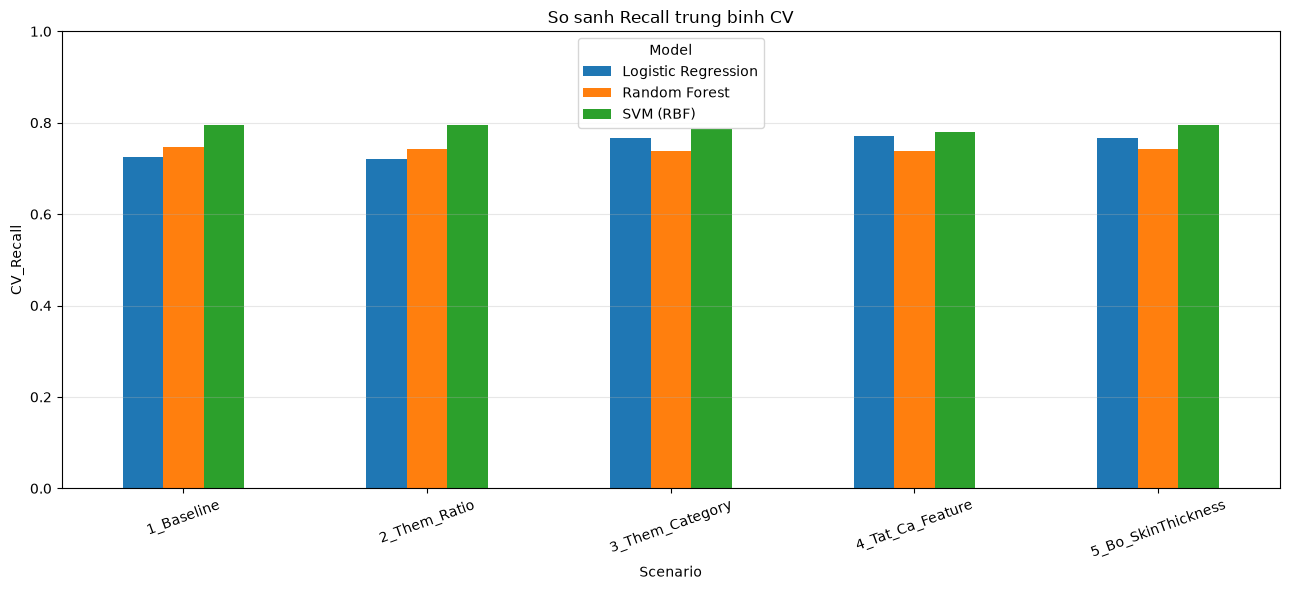

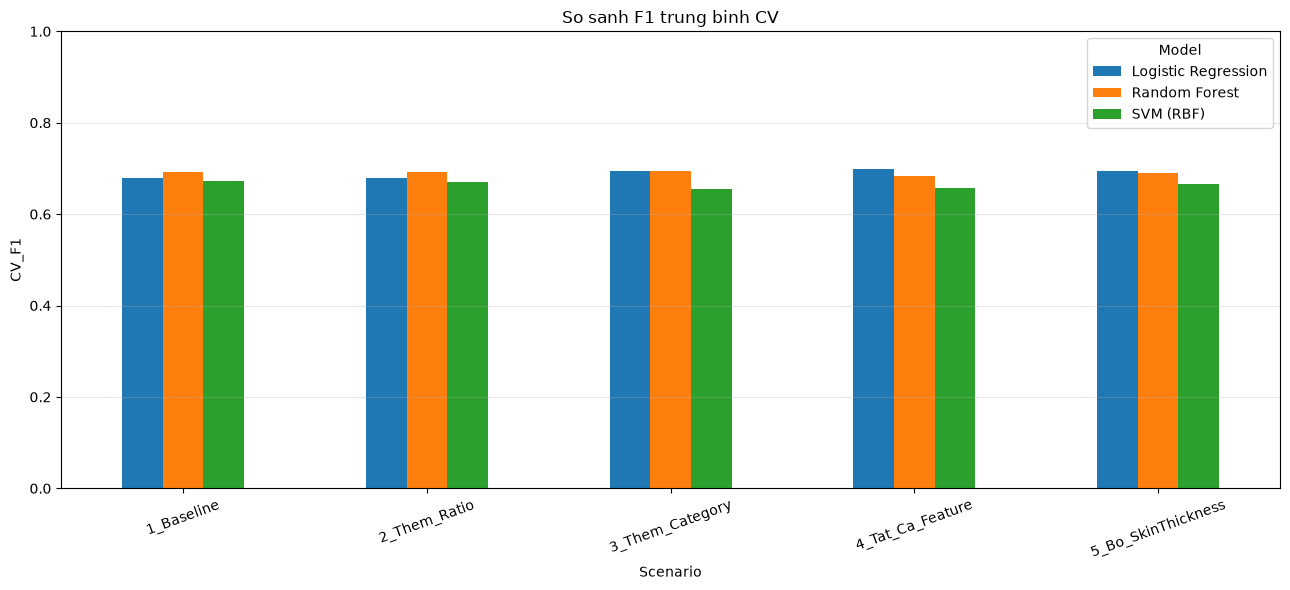

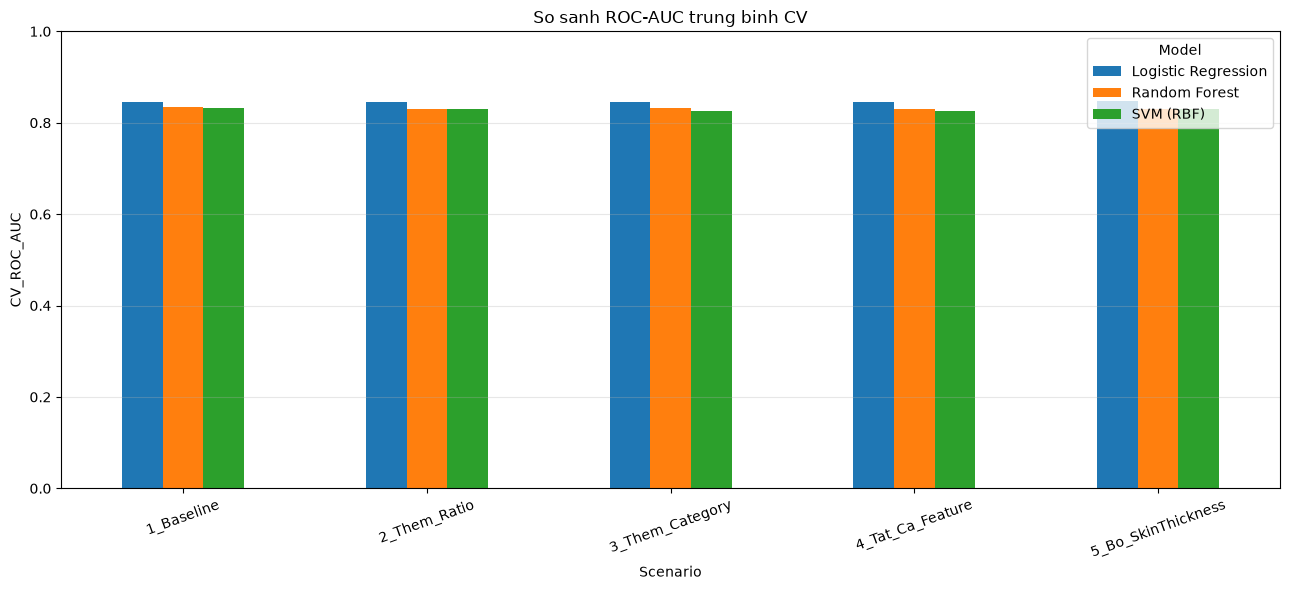

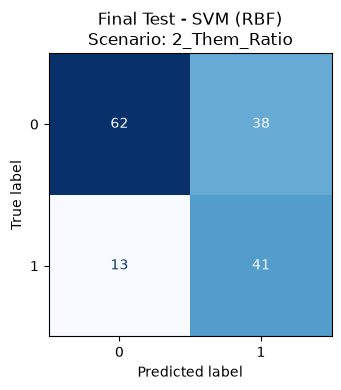


KET QUA GRIDSEARCHCV - TRAIN
          Scenario             Mo_Hinh Class_Weight  CV_Recall  CV_F1  CV_ROC_AUC  CV_Accuracy
      2_Them_Ratio           SVM (RBF)     balanced     0.7947 0.6713      0.8303       0.7296
        1_Baseline           SVM (RBF)     balanced     0.7946 0.6717      0.8321       0.7296
5_Bo_SkinThickness           SVM (RBF)     balanced     0.7946 0.6667      0.8292       0.7214
   3_Them_Category           SVM (RBF)     balanced     0.7853 0.6544      0.8264       0.7100
  4_Tat_Ca_Feature           SVM (RBF)     balanced     0.7806 0.6564      0.8267       0.7133
  4_Tat_Ca_Feature Logistic Regression     balanced     0.7710 0.6993      0.8461       0.7687
   3_Them_Category Logistic Regression     balanced     0.7663 0.6952      0.8444       0.7654
5_Bo_SkinThickness Logistic Regression     balanced     0.7663 0.6938      0.8473       0.7638
        1_Baseline       Random Forest     balanced     0.7477 0.6914      0.8339       0.7671
      2_Them_Ratio  

In [1]:

# ============================================================
# VIEC 15 - CHON CANDIDATE MODEL BANG CROSS-VALIDATION
# StratifiedKFold + GridSearchCV
# Uu tien Recall; F1 va ROC-AUC la rang buoc
# class_weight=None va class_weight="balanced" la 2 nhanh so sanh
#
# NGUYEN TAC:
# 1. Chi chon model bang CV tren TRAIN.
# 2. Khong dung Test de chon model.
# 3. Test chi duoc danh gia sau khi da chot model.
# 4. Ket qua luu vao Model/Viec15.
# 5. Khong tao thu muc models/plots.
# ============================================================

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. CAU HINH
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5

# Dieu kien rang buoc khi chon model:
# Cho phep F1/ROC-AUC thap hon gia tri CV tot nhat mot khoang nho.
# Trong nhom dat dieu kien, chon Recall cao nhat.
F1_TOLERANCE = 0.03
ROC_AUC_TOLERANCE = 0.03

CURRENT_DIR = Path.cwd().resolve()


def find_project_root(start):
    for folder in [start, *start.parents]:
        if (
            (folder / "Feature_Engineering").is_dir()
            and (folder / "Model").is_dir()
        ):
            return folder

    for folder in [start, *start.parents]:
        if (folder / "Model").is_dir():
            return folder

    return start


PROJECT_ROOT = find_project_root(CURRENT_DIR)
VIEC13_DIR = PROJECT_ROOT / "Model" / "Viec13"
VIEC14_DIR = PROJECT_ROOT / "Model" / "Viec14"
OUTPUT_DIR = PROJECT_ROOT / "Model" / "Viec15"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("VIEC 15 - CHON MODEL BANG CROSS-VALIDATION")
print("=" * 75)
print("Project root:", PROJECT_ROOT)
print("Thu muc Viec13:", VIEC13_DIR)
print("Thu muc Viec14:", VIEC14_DIR)
print("Thu muc output:", OUTPUT_DIR)


# ============================================================
# 2. TIM VA DOC DATASET
# ============================================================

def normalize_column_name(name):
    return (
        str(name)
        .strip()
        .replace("\ufeff", "")
        .replace(" ", "")
        .replace("-", "_")
        .lower()
    )


def read_csv_robust(path):
    errors = []

    for separator in [None, ",", ";", "\t"]:
        try:
            if separator is None:
                data = pd.read_csv(path, sep=None, engine="python")
            else:
                data = pd.read_csv(path, sep=separator)

            if data.shape[1] > 1:
                return data

        except Exception as exc:
            errors.append(str(exc))

    raise ValueError(
        f"Khong doc duoc CSV: {path}\n{errors}"
    )


def is_diabetes_dataset(path):
    try:
        sample = read_csv_robust(path)
        cols = {
            normalize_column_name(c)
            for c in sample.columns
        }

        has_glucose = "glucose" in cols
        has_bmi = "bmi" in cols
        has_target = bool(
            cols.intersection(
                {"class", "outcome", "diabetes", "target"}
            )
        )

        return has_glucose and has_bmi and has_target

    except Exception:
        return False


def find_dataset():
    preferred_paths = [
        PROJECT_ROOT / "Model" / "Tien_Xu_Li"
        / "pima-indians-diabetes.csv",

        PROJECT_ROOT / "Model" / "Tien_Xu_Li"
        / "pima_indian_diabetes.csv",

        PROJECT_ROOT / "Model" / "Viec14"
        / "pima-indians-diabetes.csv",

        PROJECT_ROOT / "pima-indians-diabetes.csv",

        PROJECT_ROOT / "Feature_Engineering" / "Viec9"
        / "pima-indians-diabetes.csv",
    ]

    for path in preferred_paths:
        if path.is_file() and is_diabetes_dataset(path):
            return path

    excluded = {
        ".git",
        ".venv",
        "venv",
        "__pycache__",
        ".ipynb_checkpoints",
    }

    for path in PROJECT_ROOT.rglob("*.csv"):
        if any(part.lower() in excluded for part in path.parts):
            continue

        # Khong xem cac bang ket qua la dataset goc
        filename = path.name.lower()
        if any(
            word in filename
            for word in [
                "classification_report",
                "model_results",
                "gridsearch",
                "cv_results",
                "comparison",
                "experiment_summary",
            ]
        ):
            continue

        if is_diabetes_dataset(path):
            return path

    raise FileNotFoundError(
        "Khong tim thay dataset Pima Indians Diabetes.\n"
        "Hay kiem tra file pima-indians-diabetes.csv "
        "trong project."
    )


DATA_PATH = find_dataset()
df = read_csv_robust(DATA_PATH)

print("\nDataset:", DATA_PATH)
print("Kich thuoc ban dau:", df.shape)


# ============================================================
# 3. CHUAN HOA TEN COT
# ============================================================

aliases = {
    "pregnancies": "Pregnancies",
    "glucose": "Glucose",
    "bloodpressure": "BloodPressure",
    "blood_pressure": "BloodPressure",
    "skinthickness": "SkinThickness",
    "skin_thickness": "SkinThickness",
    "insulin": "Insulin",
    "bmi": "BMI",
    "diabetespedigreefunction": "DiabetesPedigreeFunction",
    "diabetes_pedigree_function": "DiabetesPedigreeFunction",
    "age": "Age",
    "class": "Class",
    "outcome": "Outcome",
    "diabetes": "Diabetes",
    "target": "Target",
}

rename_map = {}

for column in df.columns:
    key = normalize_column_name(column)

    if key in aliases:
        rename_map[column] = aliases[key]

df = df.rename(columns=rename_map)

TARGET_CANDIDATES = [
    "Class",
    "Outcome",
    "Diabetes",
    "Target",
]

TARGET_COL = next(
    (col for col in TARGET_CANDIDATES if col in df.columns),
    None,
)

if TARGET_COL is None:
    raise ValueError(
        "Khong tim thay cot target.\n"
        f"Cac cot hien co: {df.columns.tolist()}"
    )

BASE_FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]

missing_features = [
    col for col in BASE_FEATURES
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        f"Dataset thieu cac cot: {missing_features}"
    )

for col in BASE_FEATURES + [TARGET_COL]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=[TARGET_COL]).copy()
df = df[df[TARGET_COL].isin([0, 1])].copy()
df[TARGET_COL] = df[TARGET_COL].astype(int)

df = df[BASE_FEATURES + [TARGET_COL]].copy()

# Xu ly cac gia tri 0 bat thuong theo quy uoc Pima.
# Viec thay 0 bang NaN duoc thuc hien truoc khi chia tap.
ZERO_AS_MISSING = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

for col in ZERO_AS_MISSING:
    df.loc[df[col] == 0, col] = np.nan

X = df[BASE_FEATURES].copy()
y = df[TARGET_COL].copy()

if y.nunique() != 2:
    raise ValueError("Target phai co du hai lop 0 va 1.")

print("Target:", TARGET_COL)
print("So dong sau lam sach:", len(df))
print("Phan bo target:")
print(y.value_counts().sort_index())


# ============================================================
# 4. TACH TRAIN VA TEST
# ============================================================

# Test duoc tach rieng va khong tham gia GridSearchCV.
# Tuyet doi khong dung Test de chon candidate model.

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("\nTrain:", X_train_raw.shape)
print("Test :", X_test_raw.shape)
print("CV chi chay tren Train.")


# ============================================================
# 5. TAI CAC FEATURE SCENARIO TU VIEC 13
# ============================================================

SCENARIOS = {
    "1_Baseline": "8 feature goc",
    "2_Them_Ratio": "Them Glucose_BMI_Ratio",
    "3_Them_Category": "Them BMI/Age category",
    "4_Tat_Ca_Feature": "Ratio va category va feature phu",
    "5_Bo_SkinThickness": "Feature engineered, bo SkinThickness",
}


def make_features(X_input, scenario):
    Z = X_input[BASE_FEATURES].copy()

    if scenario in [
        "2_Them_Ratio",
        "3_Them_Category",
        "4_Tat_Ca_Feature",
        "5_Bo_SkinThickness",
    ]:
        Z["Glucose_BMI_Ratio"] = (
            Z["Glucose"]
            / Z["BMI"].replace(0, np.nan)
        )

    if scenario in [
        "3_Them_Category",
        "4_Tat_Ca_Feature",
        "5_Bo_SkinThickness",
    ]:
        Z["BMI_Category"] = pd.cut(
            Z["BMI"],
            bins=[-np.inf, 18.5, 25, 30, np.inf],
            labels=[
                "Underweight",
                "Normal",
                "Overweight",
                "Obese",
            ],
        ).astype("object")

        Z["Age_Category"] = pd.cut(
            Z["Age"],
            bins=[-np.inf, 30, 45, np.inf],
            labels=[
                "Young",
                "Middle",
                "Older",
            ],
        ).astype("object")

    if scenario in [
        "4_Tat_Ca_Feature",
        "5_Bo_SkinThickness",
    ]:
        Z["Glucose_Insulin_Ratio"] = (
            Z["Glucose"]
            / Z["Insulin"].replace(0, np.nan)
        )

        Z["Age_BMI_Ratio"] = (
            Z["Age"]
            / Z["BMI"].replace(0, np.nan)
        )

    if scenario == "5_Bo_SkinThickness":
        Z = Z.drop(
            columns=["SkinThickness"],
            errors="ignore",
        )

    categorical_cols = [
        col for col in ["BMI_Category", "Age_Category"]
        if col in Z.columns
    ]

    if categorical_cols:
        Z = pd.get_dummies(
            Z,
            columns=categorical_cols,
            dtype=int,
        )

    # GridSearchCV se nhan dataframe co ten cot co dinh
    Z = Z.replace([np.inf, -np.inf], np.nan)

    return Z


# Tao feature tu Train va Test rieng biet.
# Khong su dung y_test trong qua trinh chon model.
X_train_scenarios = {}
X_test_scenarios = {}
feature_records = []

for scenario, description in SCENARIOS.items():
    Xtr = make_features(X_train_raw, scenario)
    Xte = make_features(X_test_raw, scenario)

    Xte = Xte.reindex(
        columns=Xtr.columns,
        fill_value=0,
    )

    X_train_scenarios[scenario] = Xtr
    X_test_scenarios[scenario] = Xte

    feature_records.append({
        "Scenario": scenario,
        "Mo_Ta": description,
        "So_Luong_Feature": len(Xtr.columns),
        "Features": ", ".join(Xtr.columns),
    })

pd.DataFrame(feature_records).to_csv(
    OUTPUT_DIR / "Viec15_Feature_Scenarios.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 6. STRATIFIED KFOLD
# ============================================================

# Moi fold giu ty le lop 0/1 gan voi tap Train.
# shuffle=True va random_state giup tai lap ket qua.

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print("\nStratifiedKFold:")
print("So fold:", N_SPLITS)
print("Shuffle:", True)
print("Random state:", RANDOM_STATE)


# ============================================================
# 7. KHAI BAO MODEL VA GRID SEARCH
# ============================================================

# class_weight=None va "balanced" duoc so sanh trong GridSearch.
# Imputer va scaler nam trong Pipeline.
# Khong su dung SMOTE trong phien ban nay.

MODEL_CONFIGS = {
    "Logistic Regression": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=3000,
                random_state=RANDOM_STATE,
            )),
        ]),
        "param_grid": {
            "model__C": [0.1, 1.0, 10.0],
            "model__class_weight": [None, "balanced"],
            "model__solver": ["liblinear"],
        },
    },

    "Random Forest": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )),
        ]),
        "param_grid": {
            "model__n_estimators": [200, 400],
            "model__max_depth": [None, 8],
            "model__min_samples_leaf": [1, 3],
            "model__class_weight": [None, "balanced"],
        },
    },

    "SVM (RBF)": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", SVC(
                kernel="rbf",
                probability=True,
                random_state=RANDOM_STATE,
            )),
        ]),
        "param_grid": {
            "model__C": [0.1, 1.0, 10.0],
            "model__gamma": ["scale", "auto"],
            "model__class_weight": [None, "balanced"],
        },
    },
}


# ============================================================
# 8. QUY TAC CHON MODEL
# ============================================================

def refit_recall_with_constraints(cv_results):
    """
    Chon candidate theo quy tac:
    1. F1 phai nam trong nguong gan voi F1 CV cao nhat.
    2. ROC-AUC phai nam trong nguong gan voi ROC-AUC CV cao nhat.
    3. Trong cac candidate dat dieu kien, uu tien Recall cao nhat.
    4. Neu Recall bang nhau, uu tien F1, sau do ROC-AUC.

    Ham nay chi doc ket qua CV tren Train.
    """

    recall_values = np.asarray(
        cv_results["mean_test_recall"],
        dtype=float,
    )

    f1_values = np.asarray(
        cv_results["mean_test_f1"],
        dtype=float,
    )

    auc_values = np.asarray(
        cv_results["mean_test_roc_auc"],
        dtype=float,
    )

    valid = (
        np.isfinite(recall_values)
        & np.isfinite(f1_values)
        & np.isfinite(auc_values)
    )

    if not valid.any():
        raise ValueError(
            "Tat ca candidate deu co metric CV khong hop le."
        )

    max_f1 = np.nanmax(f1_values[valid])
    max_auc = np.nanmax(auc_values[valid])

    eligible = (
        valid
        & (f1_values >= max_f1 - F1_TOLERANCE)
        & (auc_values >= max_auc - ROC_AUC_TOLERANCE)
    )

    # Neu khong co candidate dat ca hai rang buoc,
    # dung fallback: toi da F1 + ROC-AUC, sau do Recall.
    if not eligible.any():
        candidates = np.flatnonzero(valid)

        chosen = max(
            candidates,
            key=lambda i: (
                f1_values[i] + auc_values[i],
                recall_values[i],
                f1_values[i],
                auc_values[i],
            ),
        )

        return int(chosen)

    candidates = np.flatnonzero(eligible)

    chosen = max(
        candidates,
        key=lambda i: (
            recall_values[i],
            f1_values[i],
            auc_values[i],
        ),
    )

    return int(chosen)


SCORING = {
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
}


# ============================================================
# 9. CHAY GRIDSEARCHCV CHO CAC SCENARIO VA MODEL
# ============================================================

all_cv_rows = []
best_candidates = []

total_searches = len(SCENARIOS) * len(MODEL_CONFIGS)
search_number = 0

for scenario, description in SCENARIOS.items():

    Xtr = X_train_scenarios[scenario]
    ytr = y_train

    print("\n" + "=" * 75)
    print("SCENARIO:", scenario)
    print(description)
    print("So feature:", Xtr.shape[1])
    print("=" * 75)

    for model_name, config in MODEL_CONFIGS.items():

        search_number += 1

        print(
            f"\n[{search_number}/{total_searches}] "
            f"GridSearchCV: {model_name}"
        )

        grid = GridSearchCV(
            estimator=config["pipeline"],
            param_grid=config["param_grid"],
            scoring=SCORING,
            refit=refit_recall_with_constraints,
            cv=cv,
            n_jobs=-1,
            verbose=0,
            return_train_score=False,
            error_score="raise",
        )

        grid.fit(Xtr, ytr)

        cv_results = pd.DataFrame(grid.cv_results_)

        # Luu toan bo tung candidate
        for candidate_idx, row in cv_results.iterrows():

            params = row["params"]

            class_weight = params.get(
                "model__class_weight",
                None,
            )

            all_cv_rows.append({
                "Scenario": scenario,
                "Mo_Ta": description,
                "Mo_Hinh": model_name,
                "Candidate_Index": int(candidate_idx),
                "Class_Weight": (
                    "balanced"
                    if class_weight == "balanced"
                    else "None"
                ),
                "Mean_CV_Recall": row["mean_test_recall"],
                "Std_CV_Recall": row["std_test_recall"],
                "Mean_CV_F1": row["mean_test_f1"],
                "Std_CV_F1": row["std_test_f1"],
                "Mean_CV_ROC_AUC": row["mean_test_roc_auc"],
                "Std_CV_ROC_AUC": row["std_test_roc_auc"],
                "Mean_CV_Accuracy": row["mean_test_accuracy"],
                "Mean_CV_Precision": row["mean_test_precision"],
                "Rank_Recall": row["rank_test_recall"],
                "Rank_F1": row["rank_test_f1"],
                "Rank_ROC_AUC": row["rank_test_roc_auc"],
                "Params": json.dumps(
                    params,
                    ensure_ascii=False,
                    default=str,
                ),
            })

        best_idx = grid.best_index_
        best_row = cv_results.iloc[best_idx]
        best_params = grid.best_params_

        best_class_weight = best_params.get(
            "model__class_weight",
            None,
        )

        best_candidate = {
            "Scenario": scenario,
            "Mo_Ta": description,
            "Mo_Hinh": model_name,
            "So_Luong_Feature": Xtr.shape[1],
            "Class_Weight": (
                "balanced"
                if best_class_weight == "balanced"
                else "None"
            ),
            "CV_Recall": float(best_row["mean_test_recall"]),
            "CV_Recall_STD": float(best_row["std_test_recall"]),
            "CV_F1": float(best_row["mean_test_f1"]),
            "CV_F1_STD": float(best_row["std_test_f1"]),
            "CV_ROC_AUC": float(best_row["mean_test_roc_auc"]),
            "CV_ROC_AUC_STD": float(best_row["std_test_roc_auc"]),
            "CV_Accuracy": float(best_row["mean_test_accuracy"]),
            "CV_Precision": float(best_row["mean_test_precision"]),
            "Best_Params": json.dumps(
                best_params,
                ensure_ascii=False,
                default=str,
            ),
        }

        best_candidates.append(best_candidate)

        print("Best params:", best_params)
        print(f"CV Recall : {best_candidate['CV_Recall']:.4f}")
        print(f"CV F1     : {best_candidate['CV_F1']:.4f}")
        print(f"CV ROC-AUC: {best_candidate['CV_ROC_AUC']:.4f}")


# ============================================================
# 10. LUU KET QUA CV VA GRIDSEARCH
# ============================================================

all_cv_df = pd.DataFrame(all_cv_rows)
best_candidates_df = pd.DataFrame(best_candidates)

all_cv_df.to_csv(
    OUTPUT_DIR / "Viec15_GridSearch_All_Candidates.csv",
    index=False,
    encoding="utf-8-sig",
)

best_candidates_df.to_csv(
    OUTPUT_DIR / "Viec15_Best_Candidate_Per_Model.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 11. CHON CANDIDATE CUOI CUNG CHI BANG CV
# ============================================================

# Xet cac candidate tot nhat cua tung cap scenario/model.
# Uu tien Recall; rang buoc F1 va ROC-AUC gan voi gia tri tot nhat.
# Khong su dung Test o buoc nay.

best_f1 = best_candidates_df["CV_F1"].max()
best_auc = best_candidates_df["CV_ROC_AUC"].max()

eligible_df = best_candidates_df[
    (best_candidates_df["CV_F1"] >= best_f1 - F1_TOLERANCE)
    & (
        best_candidates_df["CV_ROC_AUC"]
        >= best_auc - ROC_AUC_TOLERANCE
    )
].copy()

if eligible_df.empty:
    # Fallback minh bach neu khong co candidate nao dat ca hai
    # rang buoc cung luc.
    eligible_df = best_candidates_df.copy()
    eligible_df["Fallback_Score"] = (
        eligible_df["CV_F1"]
        + eligible_df["CV_ROC_AUC"]
    )

    eligible_df = eligible_df.sort_values(
        by=[
            "Fallback_Score",
            "CV_Recall",
            "CV_F1",
            "CV_ROC_AUC",
        ],
        ascending=False,
    )

    selection_reason = (
        "Fallback: khong co candidate nao dong thoi dat "
        "nguong F1 va ROC-AUC. Chon theo tong F1 + ROC-AUC, "
        "sau do Recall."
    )

else:
    eligible_df = eligible_df.sort_values(
        by=[
            "CV_Recall",
            "CV_F1",
            "CV_ROC_AUC",
        ],
        ascending=False,
    )

    selection_reason = (
        "Dat rang buoc F1 va ROC-AUC; trong nhom hop le, "
        "uu tien Recall, tiep theo F1 va ROC-AUC."
    )

selected = eligible_df.iloc[0].to_dict()

selected_scenario = selected["Scenario"]
selected_model_name = selected["Mo_Hinh"]

selected_config = MODEL_CONFIGS[selected_model_name]
selected_params = json.loads(selected["Best_Params"])

# Chuyen params JSON ve dict va fit lai tren toan bo TRAIN.
# Buoc nay van khong su dung Test de chon model.
selected_model = selected_config["pipeline"].set_params(
    **selected_params
)

X_train_selected = X_train_scenarios[selected_scenario]
X_test_selected = X_test_scenarios[selected_scenario]

selected_model.fit(X_train_selected, y_train)


# ============================================================
# 12. LUU MODEL DA CHOT VA BIEN BAN CHON MODEL
# ============================================================

# Theo yeu cau hien tai, khong tao thu muc models/plots.
# Model duoc luu truc tiep trong Model/Viec15.

import joblib

model_artifact = {
    "model": selected_model,
    "scenario": selected_scenario,
    "model_name": selected_model_name,
    "features": X_train_selected.columns.tolist(),
    "target": TARGET_COL,
    "best_params": selected_params,
    "selection_method": "StratifiedKFold + GridSearchCV",
    "selection_data": "TRAIN only",
    "selection_metric": "Recall with F1/ROC-AUC constraints",
    "f1_tolerance": F1_TOLERANCE,
    "roc_auc_tolerance": ROC_AUC_TOLERANCE,
    "random_state": RANDOM_STATE,
    "n_splits": N_SPLITS,
}

joblib.dump(
    model_artifact,
    OUTPUT_DIR / "Viec15_Selected_Model.joblib",
)

# Bien ban chon model: chi ghi cac metric CV.
selection_memo = {
    "Tieu_de": "BIEN BAN CHON CANDIDATE MODEL - VIEC 15",
    "Dataset": str(DATA_PATH),
    "Target": TARGET_COL,
    "Phuong_phap": "StratifiedKFold + GridSearchCV",
    "So_Fold": N_SPLITS,
    "Du_Lieu_Chon_Model": "TRAIN only",
    "Khong_Dung_Test_De_Chon_Model": True,
    "Metric_Uu_Tien": "Recall",
    "Rang_Buoc_F1": (
        f"CV_F1 >= F1_tot_nhat - {F1_TOLERANCE}"
    ),
    "Rang_Buoc_ROC_AUC": (
        f"CV_ROC_AUC >= ROC_AUC_tot_nhat - {ROC_AUC_TOLERANCE}"
    ),
    "Nhanh_Class_Weight": [
        "None",
        "balanced",
    ],
    "Scenario_Da_Danh_Gia": list(SCENARIOS.keys()),
    "Model_Da_Danh_Gia": list(MODEL_CONFIGS.keys()),
    "Scenario_Duoc_Chon": selected_scenario,
    "Model_Duoc_Chon": selected_model_name,
    "Class_Weight_Duoc_Chon": selected["Class_Weight"],
    "Best_Params": selected_params,
    "CV_Recall": float(selected["CV_Recall"]),
    "CV_F1": float(selected["CV_F1"]),
    "CV_ROC_AUC": float(selected["CV_ROC_AUC"]),
    "CV_Accuracy": float(selected["CV_Accuracy"]),
    "CV_Precision": float(selected["CV_Precision"]),
    "Ly_Do_Chon": selection_reason,
    "Ghi_Chu": (
        "Khong su dung metric tren Test de chon candidate. "
        "Test chi duoc danh gia sau khi model da duoc chot."
    ),
}

with open(
    OUTPUT_DIR / "Viec15_Bien_Ban_Chon_Model.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        selection_memo,
        file,
        ensure_ascii=False,
        indent=4,
    )

memo_table = pd.DataFrame([
    {"Noi_Dung": "Scenario duoc chon", "Gia_Tri": selected_scenario},
    {"Noi_Dung": "Model duoc chon", "Gia_Tri": selected_model_name},
    {"Noi_Dung": "Class weight", "Gia_Tri": selected["Class_Weight"]},
    {"Noi_Dung": "CV Recall", "Gia_Tri": round(selected["CV_Recall"], 4)},
    {"Noi_Dung": "CV F1", "Gia_Tri": round(selected["CV_F1"], 4)},
    {"Noi_Dung": "CV ROC-AUC", "Gia_Tri": round(selected["CV_ROC_AUC"], 4)},
    {"Noi_Dung": "CV Accuracy", "Gia_Tri": round(selected["CV_Accuracy"], 4)},
    {"Noi_Dung": "So fold", "Gia_Tri": N_SPLITS},
    {"Noi_Dung": "Du lieu chon model", "Gia_Tri": "TRAIN only"},
    {"Noi_Dung": "Quy tac", "Gia_Tri": selection_reason},
])

memo_table.to_csv(
    OUTPUT_DIR / "Viec15_Bien_Ban_Chon_Model.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 13. XUAT BANG SO SANH CV THÀNH PNG
# ============================================================

def save_table_png(dataframe, filepath, title, max_rows=40):
    """
    Xuat dataframe thanh anh PNG bang matplotlib.
    Khong dung pandas Styler/Jinja2.
    """
    data = dataframe.copy().head(max_rows)

    # Lam gon gia tri so de bang de doc
    for col in data.columns:
        if pd.api.types.is_float_dtype(data[col]):
            data[col] = data[col].map(
                lambda x: f"{x:.4f}" if pd.notna(x) else ""
            )

    n_rows, n_cols = data.shape

    fig_width = max(12, min(24, n_cols * 2.0))
    fig_height = max(3.5, min(18, (n_rows + 2) * 0.42))

    fig, ax = plt.subplots(
        figsize=(fig_width, fig_height)
    )

    ax.axis("off")
    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=18,
    )

    table = ax.table(
        cellText=data.values,
        colLabels=data.columns,
        cellLoc="center",
        colLoc="center",
        loc="center",
    )

    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1, 1.35)

    for (row, col), cell in table.get_celld().items():
        if row == 0:
            cell.set_text_props(
                weight="bold",
                color="white",
            )
            cell.set_facecolor("#24527a")
        else:
            cell.set_facecolor(
                "#eef4f8" if row % 2 == 0 else "white"
            )

    fig.tight_layout()
    fig.savefig(
        filepath,
        dpi=200,
        bbox_inches="tight",
    )
    plt.close(fig)


# Bang tat ca candidate co the rat dai.
# CSV luu day du; PNG chi hien thi toi da 40 dong de doc ro rang.
save_table_png(
    best_candidates_df.sort_values(
        by=["CV_Recall", "CV_F1", "CV_ROC_AUC"],
        ascending=False,
    ),
    OUTPUT_DIR / "Viec15_Best_Candidates.png",
    "Viec 15 - Best Candidate cua tung Scenario/Model",
)

save_table_png(
    eligible_df,
    OUTPUT_DIR / "Viec15_Candidates_Dat_Rang_Buoc.png",
    "Viec 15 - Candidate dat rang buoc F1 va ROC-AUC",
)

save_table_png(
    memo_table,
    OUTPUT_DIR / "Viec15_Bien_Ban_Chon_Model.png",
    "Viec 15 - Bien ban chon model",
)


# ============================================================
# 14. VE BIEU DO SO SANH KET QUA CV VA LUU PNG
# ============================================================

# Bieu do chi dung metric CV tren TRAIN.
# Khong co metric Test trong bieu do chon model.

plot_df = best_candidates_df.copy()

for metric, title, filename in [
    ("CV_Recall", "So sanh Recall trung binh CV", "Viec15_CV_Recall.png"),
    ("CV_F1", "So sanh F1 trung binh CV", "Viec15_CV_F1.png"),
    ("CV_ROC_AUC", "So sanh ROC-AUC trung binh CV", "Viec15_CV_ROC_AUC.png"),
]:
    pivot = plot_df.pivot(
        index="Scenario",
        columns="Mo_Hinh",
        values=metric,
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(13, 6),
        rot=20,
    )

    ax.set_title(title)
    ax.set_xlabel("Scenario")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Model")

    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


# ============================================================
# 15. KIEM TRA TEST SAU KHI DA CHOT MODEL
# ============================================================

# Phan nay chi danh gia model da duoc chon.
# Tuyet doi khong quay lai chon candidate dua tren ket qua Test.

y_test_pred = selected_model.predict(X_test_selected)

if hasattr(selected_model, "predict_proba"):
    y_test_score = selected_model.predict_proba(
        X_test_selected
    )[:, 1]
else:
    y_test_score = selected_model.decision_function(
        X_test_selected
    )

test_metrics = {
    "Scenario_Da_Chot": selected_scenario,
    "Model_Da_Chot": selected_model_name,
    "Accuracy_Test": accuracy_score(y_test, y_test_pred),
    "Precision_Test": precision_score(
        y_test, y_test_pred, zero_division=0
    ),
    "Recall_Test": recall_score(
        y_test, y_test_pred, zero_division=0
    ),
    "F1_Test": f1_score(
        y_test, y_test_pred, zero_division=0
    ),
    "ROC_AUC_Test": roc_auc_score(
        y_test, y_test_score
    ),
}

# Ghi rieng de tranh nham lan voi ket qua CV.
pd.DataFrame([test_metrics]).to_csv(
    OUTPUT_DIR / "Viec15_Final_Test_Evaluation_After_Selection.csv",
    index=False,
    encoding="utf-8-sig",
)

# Classification report tren Test sau khi chot model
test_report = classification_report(
    y_test,
    y_test_pred,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(test_report).transpose().to_csv(
    OUTPUT_DIR / "Viec15_Final_Test_Classification_Report.csv",
    encoding="utf-8-sig",
)

# Confusion matrix tren Test sau khi chot model
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1],
)

fig, ax = plt.subplots(figsize=(5, 4))

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1],
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
)

ax.set_title(
    f"Final Test - {selected_model_name}\n"
    f"Scenario: {selected_scenario}"
)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "Viec15_Final_Test_Confusion_Matrix.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# ============================================================
# 16. LUU CAU HINH THUC NGHIEM
# ============================================================

config = {
    "project_root": str(PROJECT_ROOT),
    "dataset_path": str(DATA_PATH),
    "output_dir": str(OUTPUT_DIR),
    "target_column": TARGET_COL,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "n_splits": N_SPLITS,
    "cv_method": "StratifiedKFold",
    "search_method": "GridSearchCV",
    "scoring": list(SCORING.keys()),
    "selection_priority": "Recall",
    "f1_tolerance": F1_TOLERANCE,
    "roc_auc_tolerance": ROC_AUC_TOLERANCE,
    "class_weight_options": [None, "balanced"],
    "scenarios": SCENARIOS,
    "models": list(MODEL_CONFIGS.keys()),
    "selected_scenario": selected_scenario,
    "selected_model": selected_model_name,
    "selected_class_weight": selected["Class_Weight"],
    "selected_params": selected_params,
    "selection_uses_test": False,
}

with open(
    OUTPUT_DIR / "Viec15_Experiment_Config.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        config,
        file,
        ensure_ascii=False,
        indent=4,
        default=str,
    )


# ============================================================
# 17. IN KET QUA CUOI CUNG
# ============================================================

print("\n" + "=" * 75)
print("KET QUA GRIDSEARCHCV - TRAIN")
print("=" * 75)

display_cols = [
    "Scenario",
    "Mo_Hinh",
    "Class_Weight",
    "CV_Recall",
    "CV_F1",
    "CV_ROC_AUC",
    "CV_Accuracy",
]

print(
    best_candidates_df[display_cols]
    .sort_values(
        by=["CV_Recall", "CV_F1", "CV_ROC_AUC"],
        ascending=False,
    )
    .round(4)
    .to_string(index=False)
)

print("\n" + "=" * 75)
print("BIEN BAN CHON MODEL")
print("=" * 75)

print("Scenario:", selected_scenario)
print("Model:", selected_model_name)
print("Class weight:", selected["Class_Weight"])
print("Best params:", selected_params)
print(f"CV Recall:  {selected['CV_Recall']:.4f}")
print(f"CV F1:      {selected['CV_F1']:.4f}")
print(f"CV ROC-AUC: {selected['CV_ROC_AUC']:.4f}")
print("Ly do:", selection_reason)

print("\nTEST - CHI DANH GIA SAU KHI DA CHOT MODEL")
for key, value in test_metrics.items():
    if isinstance(value, (int, float, np.integer, np.floating)):
        print(f"{key}: {float(value):.4f}")
    else:
        print(f"{key}: {value}")

print("\n" + "=" * 75)
print("CAC FILE DA LUU TRONG MODEL/VIEC15")
print("=" * 75)

for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print("-", path.name)

print("\nHoan thanh Viec 15.")
